# Die Dunkelwolke ρ Ophiuchi

Das Notebook misst die Staubwolke von ρ Ophiuchi auf drei unabhängige Weisen: als Extinktion der Sterne dahinter (Farben aus 2MASS, eine Karte nach Art von NICER), als Wärmestrahlung (modifizierter Schwarzkörper an IRIS 100 µm und Planck 857, 545 und 353 GHz in jedem Pixel) und als Sprung der Extinktion in den Gaia-Daten, aus dem eine Maximum-Likelihood-Methode die Entfernung bestimmt. Daraus folgen Masse, Temperatur und Heizung des Staubs durch einen B-Stern, das Extinktionsgesetz und das Verhältnis von Absorption zu Emission; verglichen wird mit VLBI-Parallaxen und der Staubkarte von Schlegel, Finkbeiner & Davis.

Wie weit ist eine Wolke entfernt, die man nur als Loch zwischen den Sternen sieht, wie viel wiegt sie, und wie warm ist ihr Staub?

#### **Hintergrund**

Der Überlieferung nach stieß William Herschel 1784 im Skorpion auf eine Stelle ohne Sterne und rief: „Hier ist wahrhaftig ein Loch im Himmel.“ Erst Edward Emerson Barnard, der ab 1889 die Milchstraße fotografierte, und Max Wolf, der 1923 die Sterne vor und hinter solchen Flecken zählte, zeigten, dass es Wolken sind, die das Licht dahinter verschlucken. 1930 wies Robert Trumpler an Sternhaufen nach, dass der Staub die ganze Milchstraße durchzieht und alle Entfernungen verfälscht, die ihn nicht berücksichtigen.

Heute weiß man, dass in solchen Dunkelwolken Sterne entstehen. Die Wolke um ρ Ophiuchi, 140 pc entfernt, ist eine der nächsten: In ihrem dichten Kern L1688 sitzen einige hundert junge Sterne, die man im Infraroten sieht, im Optischen nicht. Forschende kartieren solche Wolken auf drei Wegen. Mit den Farben der Sterne dahinter messen sie die Extinktion (seit Lada et al. 1994 mit Infrarotkameras, seit 2MASS für ganze Wolkenkomplexe). Mit der Wärmestrahlung des Staubs messen sie Säule und Temperatur (IRAS, Herschel, Planck). Und mit Gaia messen sie seit 2018, in welcher Entfernung die Extinktion einsetzt, und bauen dreidimensionale Staubkarten der Umgebung der Sonne.

Dieses Notebook geht alle drei Wege für dieselbe Wolke und vergleicht sie.

<a id="landkarte"></a>Landkarte:

- **Daten**
  - [Die Wolke in sechs Bändern (Schritt 1)](#exp-1): im Blauen ein dunkles Band mit Reflexionsnebeln, im fernen Infraroten hell; bei 100 µm leuchtet der warme Staub an HD 147889, bei 850 µm der kalte Kern.
  - [Sterne in Richtung der Wolke (Schritt 2)](#exp-2): 2MASS sieht im dichtesten Teil noch 4.9 Sterne pro Pixel, Gaia 0.3.
- **Reduktion**
  - [Farben ohne und mit Staub (Schritt 3)](#exp-3): Eigenfarben (H−K)₀ = 0.090 und (J−H)₀ = 0.450 aus dem Kontrollfeld; die Wolke schiebt die Sterne entlang des Rötungsvektors.
  - [Die Extinktionskarte (Schritt 4)](#exp-4): A_V im Median 3.5 mag, im Kern über 20 mag; Rangkorrelation 0.91 mit Planck.
- **Eigene Messung**
  - [Rötung gegen Entfernung (Schritt 5)](#exp-5): Die Extinktion springt zwischen 130 und 140 pc von 0.5 auf über 3 mag.
  - [Wie warm ist der Staub? (Schritt 6)](#exp-6): 20.8 K im Median, 18.3 K in den dichtesten Pixeln, 36.6 K neben HD 147889.
  - [Ein Stern heizt den Staub (Schritt 7)](#exp-7): Die Heizleistung von HD 147889 fällt mit r^(−2.10 ± 0.13), dem Abstandsgesetz.
- **Modell und Fit**
  - [Die Entfernung aus dem Sprung (Schritt 8)](#exp-8): 131.5 ± 1.0 pc aus 979 Sternen.
  - [Das Extinktionsgesetz im Infraroten (Schritt 9)](#exp-9): E(J−H)/E(H−K) = 1.653 ± 0.011; ohne richtige Gewichtung käme 1.99 heraus.
  - [Staub, der verdeckt, gegen Staub, der leuchtet (Schritt 10)](#exp-10): A_V/τ353 ist 18 % kleiner als im diffusen Gas, im kalten Kern noch kleiner.
  - [Die Masse der Wolke (Schritt 11)](#exp-11): 4500 M☉ über A_V = 1, davon 35 % über A_V = 7.
- **Eigene Messung gegen den Katalog**
  - [Die Entfernung gegen VLBI und Hipparcos (Schritt 12)](#exp-12): 6 pc vor den jungen Sternen, die VLBI misst; Hipparcos gab 119 pc.
  - [Die Extinktion gegen die Staubkarte von Schlegel, Finkbeiner & Davis (Schritt 13)](#exp-13): SFD liegt im Median 24 % zu hoch, in warmem Staub viel mehr, neben HD 147889 um den Faktor 5.

Verwandte Notebooks: Rötung aus dem Balmer-Dekrement und die Staubkarte auf M 31 in [Planetarische Nebel](https://github.com/deltorobarba/science/blob/main/astro/nebulae_planetary.ipynb); Gaia-Parallaxen und Astrometrie in [Der Krebsnebel](https://github.com/deltorobarba/science/blob/main/astro/nebulae_crab.ipynb); Staub in einer anderen Galaxie in [Photometrie einer Galaxie](https://github.com/deltorobarba/science/blob/main/astro/galaxies_photometry.ipynb); Planck-Karten bei 100 und 143 GHz, wo die Hintergrundstrahlung heller ist als der Staub, in [Die akustischen Peaks](https://github.com/deltorobarba/science/blob/main/astro/cosmology_cmbpeaks.ipynb); Staubtemperatur, Extinktion aus 2MASS-Farben und Heizung durch einen O-Stern in einem H-II-Gebiet in [Der Orionnebel](https://github.com/deltorobarba/science/blob/main/astro/nebulae_orion.ipynb).

#### **Theorie**

##### *1. Staub und Dunkelwolken*

Interstellarer Staub besteht aus Körnern von Silikaten und Kohlenstoff, meist kleiner als ein Mikrometer, oft mit einem Mantel aus Eis. Er macht nur etwa ein Prozent der Masse des interstellaren Gases aus, prägt aber, was wir sehen: Er schluckt und streut das Licht der Sterne, besonders das blaue, und gibt die aufgenommene Energie als Wärmestrahlung im fernen Infrarot wieder ab.

In **Molekülwolken** ist das Gas so dicht (10² bis 10⁵ Teilchen pro cm³) und kalt (10 bis 20 K), dass Wasserstoff als H₂ vorliegt. Der Staub schirmt das Innere gegen ultraviolettes Licht ab, die Moleküle überleben, und in den dichtesten Kernen kollabiert das Gas zu Sternen. Die Wolke von ρ Ophiuchi ist eine der nächsten Sternentstehungsregionen: In ihrem Kern L1688 bilden sich gerade einige hundert Sterne, die meisten im Optischen unsichtbar.

**Fachbegriffe:**
- **Molekülwolke:** eine Wolke aus kaltem, dichtem Gas, überwiegend H₂, mit typisch 10³ bis 10⁶ Sonnenmassen.
- **Junge Sterne (YSOs):** Sterne, die noch Gas aus ihrer Umgebung aufnehmen oder eine Scheibe haben; sie leuchten im Infraroten stärker als normale Sterne.

##### *2. Extinktion, Rötung und die Farben im Infraroten*

Eine Staubsäule schwächt das Licht eines Sterns bei der Wellenlänge λ um $A_\lambda$ Magnituden. Weil $A_\lambda$ mit λ fällt, wird der Stern auch röter: Sein Farbindex steigt um den **Farbexzess**

$$E(\lambda_1 - \lambda_2) = A_{\lambda_1} - A_{\lambda_2}.$$

Im nahen Infrarot gilt nach Rieke & Lebofsky (1985) $A_J : A_H : A_K = 0.282 : 0.175 : 0.112$ in Einheiten von $A_V$. Aus der gemessenen Farbe $(H-K)$ und der Eigenfarbe $(H-K)_0$ folgt deshalb

$$A_V = \frac{(H-K) - (H-K)_0}{A_H/A_V - A_K/A_V} = 15.9\,\left[(H-K) - (H-K)_0\right],$$

und ebenso $A_V = 9.3\,[(J-H) - (J-H)_0]$. Die Eigenfarben der meisten Sterne liegen im Infraroten dicht beieinander, $(H-K)_0 \approx 0.1$ mit einer Streuung von etwa 0.07 mag; ein einzelner Stern gibt deshalb A_V auf gut 1 mag genau, der Median vieler Sterne viel genauer. Beide Farben zusammen, gewichtet mit ihren Fehlern, sind die Grundidee von NICER (Lombardi & Alves 2001).

##### *3. Von der Extinktion zur Masse*

Staub und Gas sind in der Milchstraße gut gemischt. Bohlin, Savage & Drake (1978) fanden mit dem UV-Satelliten Copernicus aus der Lyman-α-Absorption

$$N_\mathrm{H} = 5.8\cdot10^{21}\,\mathrm{cm^{-2}}\cdot E(B-V) = 1.87\cdot10^{21}\,\mathrm{cm^{-2}}\cdot A_V \qquad (R_V = 3.1),$$

wobei $N_\mathrm{H}$ alle Wasserstoffatome zählt, auch die in H₂. Mit Helium wiegt jedes Wasserstoffatom im Mittel $1.37\,m_\mathrm{H}$, die Masse pro Fläche ist $\Sigma = 1.37\,m_\mathrm{H} N_\mathrm{H}$, und ein Pixel mit Kantenlänge $\theta$ (im Bogenmaß) in der Entfernung $d$ enthält

$$M = 1.37\,m_\mathrm{H}\cdot 1.87\cdot10^{21}\,A_V\cdot(\theta d)^2 .$$

Die Masse wächst mit $d^2$; ein Fehler von 5 % in der Entfernung macht 10 % in der Masse.

##### *4. Die Wärmestrahlung des Staubs*

Ein Staubkorn im Strahlungsgleichgewicht strahlt so viel ab, wie es absorbiert. Seine Absorption im Sichtbaren ist fast unabhängig von der Temperatur, seine Emission im fernen Infrarot dagegen hat die Form eines **modifizierten Schwarzkörpers**:

$$I_\nu = \tau_{353}\left(\frac{\nu}{353\ \mathrm{GHz}}\right)^{\beta} B_\nu(T),$$

weil Körner, die viel kleiner als die Wellenlänge sind, mit einem Wirkungsquerschnitt $\propto \nu^\beta$ strahlen ($\beta \approx 1.5$ bis 2). Die abgestrahlte Leistung pro Korn wächst damit wie $T^{4+\beta}$. Heizt ein Stern der Leuchtkraft $L$ das Korn im Abstand $r$, ist der absorbierte Fluss $\propto L/r^2$, und

$$T \propto L^{1/(4+\beta)}\, r^{-2/(4+\beta)} \approx r^{-0.36} \quad (\beta = 1.6).$$

Kommt die gleichmäßige Heizung durch das interstellare Strahlungsfeld dazu, addieren sich die Leistungen: $T^{4+\beta} = T_b^{4+\beta}\,[1 + (r_0/r)^2]$, wobei $r_0$ der Abstand ist, in dem der Stern so stark heizt wie die übrige Milchstraße.

Die optische Tiefe $\tau_{353}$ ist proportional zur Säule Staub; das Verhältnis $A_V/\tau_{353}$ misst, wie viel Licht ein Korn im Sichtbaren schluckt im Verhältnis dazu, wie viel es im Submillimeterbereich strahlt. Planck hat an Quasaren hoher galaktischer Breite $E(B-V)/\tau_{353} = 1.49\cdot10^4$ gemessen, also $A_V/\tau_{353} = 4.6\cdot10^4$ im diffusen Gas.

##### *5. Entfernung aus dem Sprung der Extinktion*

Liegt der Staub einer Wolke in einer dünnen Schicht in der Entfernung $d_c$, haben Sterne davor fast keine Extinktion und Sterne dahinter die volle. Für einen Stern mit gemessener Parallaxe $\varpi \pm \sigma$ ist die Wahrscheinlichkeit, vor der Wolke zu stehen,

$$P_\text{vorn} = \Phi\!\left(\frac{\varpi - 1000/d_c}{\sigma}\right)$$

mit der Normalverteilungsfunktion $\Phi$. Die Likelihood eines Sterns mit Extinktion $A$ ist dann

$$L = (1-f)\left[P_\text{vorn}\,\mathcal{N}(A; a_0, s_0) + (1 - P_\text{vorn})\,\mathcal{N}(A; a_1, s_1)\right] + \frac{f}{A_\text{max}},$$

mit einem kleinen Fremdanteil $f$ für Sterne, deren Extinktion falsch geschätzt ist. Das Produkt über alle Sterne, maximiert über $d_c$, gibt die Entfernung. Die Methode stammt aus der Zeit von Hipparcos (Lombardi, Lada & Alves 2008); mit Gaia und Millionen Sternen haben Zucker et al. (2019) so die Entfernungen fast aller nahen Molekülwolken gemessen.

#### **Daten**

- **Bilder** vom Dienst SkyView der NASA, alle auf dasselbe Gitter von 3° × 3° um L1688 gerechnet: die digitalisierten Palomar-Platten DSS2 in Blau und Rot, WISE bei 12 µm, IRAS bei 100 µm in der Neubearbeitung IRIS und Planck bei 857, 545 und 353 GHz (350, 550 und 850 µm). Für die Rechnungen ein grobes Gitter mit 3′ pro Pixel, für die Bilder ein feines mit 0.9′.
- **2MASS-Punktquellenkatalog** über den TAP-Dienst von IRSA (Caltech): Helligkeiten J, H, K_s mit Fehlern und Qualitätsflaggen für alle Sterne im Feld und in einem Kontrollfeld mit wenig Staub 5.5° südwestlich (bei derselben galaktischen Breite).
- **Gaia DR3** über den TAP-Dienst der ESA: Parallaxe und die Extinktion A_G, die die Gaia-Pipeline GSP-Phot aus dem BP/RP-Spektrum jedes Sterns schätzt, für alle Sterne mit Parallaxe S/N > 5.
- **Staubkarte** von Schlegel, Finkbeiner & Davis (1998) und die Rötung des Kontrollfelds nach Schlafly & Finkbeiner (2011) vom Staubdienst bei IRSA.

Alle Downloads landen einmalig in `astrodata/dust` neben dem Notebook (zusammen etwa 15 MB).

**Hintergrund & Fachbegriffe:**
- **2MASS:** Two Micron All Sky Survey (1997 bis 2001), der ganze Himmel in J (1.25 µm), H (1.65 µm) und K_s (2.16 µm); im nahen Infrarot dringt Licht zehnmal tiefer durch Staub als im Sichtbaren.
- **WISE 12 µm:** Der Infrarotsatellit WISE (2010) sieht bei 12 µm sehr kleine, kurz auf einige hundert Kelvin aufgeheizte Körner und große Moleküle (PAH), also Staub, der von nahen heißen Sternen beleuchtet wird.
- **IRIS:** Improved Reprocessing of the IRAS Survey (Miville-Deschênes & Lagache 2005), die IRAS-Karten von 1983 mit besserer Kalibrierung und Nullpunkt; 100 µm mit 4.3′ Auflösung.
- **Planck-Karten:** Der Satellit Planck (2009 bis 2013) hat den Himmel in neun Frequenzen kartiert; bei 353 bis 857 GHz sieht er fast nur die Wärmestrahlung des Staubs. Die Karte bei 353 GHz ist in K_CMB angegeben (Temperatureinheit der Hintergrundstrahlung), die bei 545 und 857 GHz in MJy/sr.
- **GSP-Phot:** General Stellar Parametrizer from Photometry, die Gaia-Pipeline, die aus BP/RP-Spektrum, Helligkeit und Parallaxe Temperatur, Schwerebeschleunigung und Extinktion jedes Sterns schätzt.

In [1]:
import io
import os
import re
import time
import urllib.parse
import urllib.request
from pathlib import Path

# Downloads landen im Ordner "astrodata" neben dem Notebook statt in den Caches im Home-Verzeichnis.
# Das muss vor dem ersten Import von astropy passieren; sonst den Kernel neu starten.
ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, special, stats
from scipy.ndimage import map_coordinates
from astropy.io import fits
from astropy.wcs import WCS

RA0, DE0, SIZE = 247.0, -24.2, 3.0   # Mitte und Kantenlänge des Feldes [°]: L1688, L1689 und ρ Oph
NPIX_MAP, NPIX_IMG = 60, 200         # Pixel des Rechengitters (3′) und der Bilder (0.9′)
CTRL = (241.0, -29.0, 1.0)           # Kontrollfeld mit wenig Staub: Mitte und Radius [°] (Schritt 3)
R_JHK = {"J": 0.282, "H": 0.175, "K": 0.112}   # A_λ / A_V im nahen Infrarot (Rieke & Lebofsky 1985)
MIN_STARS = 3                        # mindestens so viele Sterne pro Pixel der Extinktionskarte (Schritt 4)
BETA_FIX = 1.6                       # Spektralindex des Staubs, wenn er nicht frei ist (Schritt 6)
K_CMB_TO_MJY = 287.45                # 353 GHz: MJy/sr pro K_CMB (Planck 2013 IX)
AV_TAU_DIFFUSE = 3.1 * 1.49e4        # A_V / τ353 im diffusen Gas (Planck 2013 XI: E(B−V)/τ353 = 1.49·10⁴)
NH_PER_AV = 1.87e21                  # Wasserstoffsäule pro A_V [cm⁻² mag⁻¹] (Bohlin et al. 1978, R_V = 3.1)
MU_H = 1.37                          # Masse pro Wasserstoffatom in Einheiten von m_H (mit Helium)
AV_CLOUD = 5.0                       # Sterne in Pixeln mit A_V über diesem Wert gelten als "auf der Wolke" (Schritt 5)
HD147889 = (246.3513, -24.4658)      # B2-Stern am Rand von L1688 (Gaia DR3 6049140417677195136)
STARS = {"ρ Oph": (246.3963, -23.4473), "HD 147889": HD147889, "22 Sco": (247.5520, -25.1153)}
rng = np.random.default_rng(42)
pd.set_option("display.width", 160)
np.seterr(divide="ignore", invalid="ignore")
H_PLANCK, K_B, C_CGS, M_H, PC, M_SUN = 6.62607e-27, 1.380649e-16, 2.99792458e10, 1.6726e-24, 3.0857e18, 1.989e33
DUST = ASTRODATA / "dust"


def download(urls, path, check=None, timeout=120, rounds=3, pause=10):
    # lädt eine Datei vom ersten Server, der antwortet, und liest sie danach aus dem Cache;
    # SkyView lehnt zu schnelle Anfragen mit einer HTML-Seite ab ("Too Many Processes"), deshalb Pausen
    path = Path(path)
    if path.exists():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    for k in range(rounds):
        for url in urls:
            try:
                with urllib.request.urlopen(url, timeout=timeout) as r:
                    data = r.read()
            except OSError:
                continue
            if check is None or check(data):
                path.write_bytes(data)
                return path
        time.sleep(pause)
    raise OSError(f"Kein Server liefert {path.name}")


fits_ok = lambda d: d[:6] == b"SIMPLE"


def skyview(survey, npix):
    url = ("https://skyview.gsfc.nasa.gov/current/cgi/runquery.pl?" +
           urllib.parse.urlencode({"Position": f"{RA0},{DE0}", "Survey": survey, "Pixels": npix, "Size": SIZE,
                                   "Return": "FITS"}))
    h = fits.open(download([url], DUST / f"sv_{survey.replace(' ', '')}_{npix}.fits", fits_ok))[0]
    return h.data.astype(float), WCS(h.header)


def tap(service, adql, path):
    # ein TAP-Ergebnis als Tabelle; die erste Zeile muss der Spaltenkopf sein, sonst ist es eine Fehlermeldung
    url = service + "?" + urllib.parse.urlencode({"REQUEST": "doQuery", "LANG": "ADQL", "FORMAT": "csv", "QUERY": adql})
    first = adql.split()[1].rstrip(",").encode()
    return pd.read_csv(download([url], path, check=lambda d: d.startswith(first), timeout=600))


IRSA_TAP = "https://irsa.ipac.caltech.edu/TAP/sync"
ESA_TAP = "https://gea.esac.esa.int/tap-server/tap/sync"
COLS_2MASS = "ra, dec, j_m, j_msigcom, h_m, h_msigcom, k_m, k_msigcom, ph_qual, cc_flg"
BOX = f"BOX('ICRS', {RA0}, {DE0}, {SIZE}, {SIZE})"

# Bilder: fein für den Blick, grob (3′) für die Rechnungen
SURVEYS = {"DSS2 Blue": "DSS2 blau (0.45 µm)", "DSS2 Red": "DSS2 rot (0.65 µm)", "WISE 12": "WISE 12 µm (warmer Staub)",
           "IRIS100": "IRIS 100 µm", "Planck 857 I": "Planck 857 GHz (350 µm)", "Planck 353 I": "Planck 353 GHz (850 µm)"}
IMG = {s: skyview(s, NPIX_IMG) for s in SURVEYS}
BANDS = {"IRIS100": 2.998e12, "Planck 857 I": 857e9, "Planck 545 I": 545e9, "Planck 353 I": 353e9}   # Frequenzen [Hz]
GRID = {s: skyview(s, NPIX_MAP)[0] for s in BANDS}
WMAP = skyview("Planck 857 I", NPIX_MAP)[1]                          # WCS des Rechengitters
for k in ("Planck 353 I",):
    GRID[k] = GRID[k] * K_CMB_TO_MJY                                 # K_CMB -> MJy/sr

# Sterne: 2MASS im Feld und im Kontrollfeld, Gaia mit Extinktion
TM = tap(IRSA_TAP, f"SELECT {COLS_2MASS} FROM fp_psc WHERE CONTAINS(POINT('ICRS', ra, dec), {BOX}) = 1",
         DUST / "2mass_field.csv")
TM_CTRL = tap(IRSA_TAP, f"SELECT {COLS_2MASS} FROM fp_psc WHERE CONTAINS(POINT('ICRS', ra, dec), "
                        f"CIRCLE('ICRS', {CTRL[0]}, {CTRL[1]}, {CTRL[2]})) = 1", DUST / "2mass_control.csv")
BOX_WIDE = f"BOX('ICRS', {RA0}, {DE0}, {SIZE / np.cos(np.radians(DE0)) + 0.1:.3f}, {SIZE + 0.1})"   # bei ESA ohne cos δ
GAIA = tap(ESA_TAP, "SELECT source_id, ra, dec, parallax, parallax_error, phot_g_mean_mag, bp_rp, ag_gspphot "
                    f"FROM gaiadr3.gaia_source WHERE 1 = CONTAINS(POINT('ICRS', ra, dec), {BOX_WIDE}) "
                    "AND parallax_over_error > 5 AND ag_gspphot IS NOT NULL", DUST / "gaia_field_wide.csv")

# Staubdienst: Rötung des Kontrollfelds (Schlafly & Finkbeiner) und die Karte von Schlegel et al. als FITS
def irsa_dust(ra, dec, size, name):
    url = f"https://irsa.ipac.caltech.edu/cgi-bin/DUST/nph-dust?locstr={ra}+{dec}+equ+j2000&regSize={size}"
    return download([url], DUST / name, check=lambda d: b"meanValueSandF" in d).read_text()


xml_ctrl = irsa_dust(CTRL[0], CTRL[1], 2 * CTRL[2], "irsa_dust_control.xml")
EBV_CTRL = float(re.search(r"<meanValueSandF>\s*([0-9.]+)", xml_ctrl).group(1))
xml_field = irsa_dust(RA0, DE0, SIZE, "irsa_dust_field.xml")
sfd_path = DUST / "sfd_field.fits"
if not sfd_path.exists():
    url = re.search(r"(https://\S+?p150Dust\.fits)", xml_field).group(1)   # temporärer Link, gilt nur kurz
    download([url], sfd_path, fits_ok)
SFD = fits.open(sfd_path)[0]

print(f"2MASS: {len(TM)} Quellen im Feld, {len(TM_CTRL)} im Kontrollfeld (E(B−V) = {EBV_CTRL:.3f} nach Schlafly & Finkbeiner)")
print(f"Gaia DR3 mit Parallaxe S/N > 5 und A_G: {len(GAIA)} Sterne")
print("Bilder:", ", ".join(f"{s} {IMG[s][0].shape[0]}²" for s in IMG), f"| Rechengitter {NPIX_MAP}² zu {SIZE * 60 / NPIX_MAP:.0f}′")
print("Medianwerte im Feld [MJy/sr]:", ", ".join(f"{s} {np.median(v):.1f}" for s, v in GRID.items()))

2MASS: 102443 Quellen im Feld, 51321 im Kontrollfeld (E(B−V) = 0.140 nach Schlafly & Finkbeiner)
Gaia DR3 mit Parallaxe S/N > 5 und A_G: 15340 Sterne
Bilder: DSS2 Blue 200², DSS2 Red 200², WISE 12 200², IRIS100 200², Planck 857 I 200², Planck 353 I 200² | Rechengitter 60² zu 3′
Medianwerte im Feld [MJy/sr]: IRIS100 118.4, Planck 857 I 57.7, Planck 545 I 17.8, Planck 353 I 4.9


**Werkzeuge: Karten, Extinktion pro Stern, modifizierter Schwarzkörper und Sprung-Likelihood** (Theorie, Abschnitte 2 bis 5). `to_map` sammelt Werte von Sternen in die Pixel des Rechengitters (Median); `fit_sed` passt in jedem Pixel einen modifizierten Schwarzkörper an vier Bänder an; `fit_jump` sucht nach der Maximum-Likelihood-Methode die Entfernung, ab der die Extinktion springt.

In [2]:
YY, XX = np.mgrid[0:NPIX_MAP, 0:NPIX_MAP]
RA_MAP, DE_MAP = WMAP.pixel_to_world_values(XX, YY)
EXT_MAP = [SIZE / 2, -SIZE / 2, -SIZE / 2, SIZE / 2]                 # Achsen in Grad relativ zur Mitte, Osten links


def offsets(ra, dec):
    # Abstand von der Feldmitte [°], Osten positiv
    return (np.asarray(ra) - RA0) * np.cos(np.radians(DE0)), np.asarray(dec) - DE0


def pixel_of(ra, dec, wcs=WMAP, n=NPIX_MAP):
    x, y = wcs.world_to_pixel_values(np.asarray(ra), np.asarray(dec))
    xi, yi = np.floor(x + 0.5).astype(int), np.floor(y + 0.5).astype(int)
    inside = (xi >= 0) & (xi < n) & (yi >= 0) & (yi < n)
    return xi, yi, inside


def to_map(ra, dec, values, min_n=MIN_STARS):
    # Median der Werte aller Sterne pro Pixel; Pixel mit weniger als min_n Sternen bleiben leer
    xi, yi, ok = pixel_of(ra, dec)
    df = pd.DataFrame({"x": xi[ok], "y": yi[ok], "v": np.asarray(values)[ok]})
    grp = df.groupby(["y", "x"])["v"]
    med, cnt = grp.median(), grp.size()
    out, n = np.full((NPIX_MAP, NPIX_MAP), np.nan), np.zeros((NPIX_MAP, NPIX_MAP), int)
    for (y, x), v in med.items():
        n[y, x] = cnt[(y, x)]
        if cnt[(y, x)] >= min_n:
            out[y, x] = v
    return out, n


def at_map(m, ra, dec):
    # Wert einer Karte an Sternorten (NaN außerhalb)
    xi, yi, ok = pixel_of(ra, dec)
    v = np.full(len(xi), np.nan)
    v[ok] = m[yi[ok], xi[ok]]
    return v


def planck_mjy(nu, T):
    return 2 * H_PLANCK * nu**3 / C_CGS**2 / np.expm1(H_PLANCK * nu / (K_B * T)) * 1e17   # [MJy/sr]


def mbb(nu, tau353, T, beta):
    # modifizierter Schwarzkörper: I_ν = τ353 (ν/353 GHz)^β B_ν(T) (Theorie, Abschnitt 4)
    return tau353 * (nu / 353e9) ** beta * planck_mjy(nu, T)


NU = np.array(list(BANDS.values()))
SED = np.stack([GRID[s] for s in BANDS])                            # 4 × 60 × 60 [MJy/sr]
SED_ERR = 0.1                                                         # 10 % relativer Fehler je Band (Kalibrierung, Nullpunkt)


def fit_sed(y, beta=None):
    # τ353, T und β (oder β fest) für eine Intensität y in vier Bändern
    if beta is None:
        f = lambda p: (mbb(NU, 10 ** p[0], p[1], p[2]) - y) / (SED_ERR * y)
        r = optimize.least_squares(f, [-4, 18, 1.6], bounds=([-8, 5, 0.5], [0, 80, 3.5]))
        return 10 ** r.x[0], r.x[1], r.x[2]
    f = lambda p: (mbb(NU, 10 ** p[0], p[1], beta) - y) / (SED_ERR * y)
    r = optimize.least_squares(f, [-4, 18], bounds=([-8, 5], [0, 80]))
    return 10 ** r.x[0], r.x[1], beta


def fit_jump(A, plx, plx_err, d_grid=np.arange(80, 220, 0.5)):
    # Extinktion A vor und hinter einer dünnen Wolke in der Entfernung d_c (Theorie, Abschnitt 5):
    # vor der Wolke N(a0, s0), dahinter N(a1, s1), dazu ein gleichverteilter Fremdanteil f;
    # P(Stern vor der Wolke) folgt aus Parallaxe und Fehler
    def nll(th, dc):
        a0, s0, a1, s1, lf = th
        if s0 <= 0.1 or s1 <= 0.1:                                      # GSP-Phot streut mindestens 0.1 mag
            return 1e12
        f = special.expit(lf)
        p_front = stats.norm.cdf((plx - 1000 / dc) / plx_err)
        L = (1 - f) * (p_front * stats.norm.pdf(A, a0, s0) + (1 - p_front) * stats.norm.pdf(A, a1, s1)) + f / 10
        return -np.sum(np.log(L))
    th0, prof = np.array([0.4, 0.2, 3.0, 1.0, -3.0]), []
    for dc in d_grid:                                                  # Profil-Likelihood über d_c, jedes Mal vom selben Start
        r = optimize.minimize(nll, th0, args=(dc,), method="Nelder-Mead", options=dict(maxiter=3000, xatol=1e-4))
        prof.append(r.fun)
    prof = np.array(prof)
    best = d_grid[np.argmin(prof)]
    r = optimize.minimize(nll, th0, args=(best,), method="Nelder-Mead", options=dict(maxiter=5000, xatol=1e-5))
    return dict(d=best, grid=d_grid, prof=prof - prof.min(), a0=r.x[0], s0=r.x[1], a1=r.x[2], s1=r.x[3],
                frac=special.expit(r.x[4]), n=len(A))


print(f"Rechengitter: Mitte ({RA0}, {DE0}), {SIZE * 60 / NPIX_MAP:.1f}′ pro Pixel; "
      f"A_V/E(H−K) = {1 / (R_JHK['H'] - R_JHK['K']):.2f}, A_V/E(J−H) = {1 / (R_JHK['J'] - R_JHK['H']):.2f}, "
      f"E(J−H)/E(H−K) = {(R_JHK['J'] - R_JHK['H']) / (R_JHK['H'] - R_JHK['K']):.2f}")

Rechengitter: Mitte (247.0, -24.2), 3.0′ pro Pixel; A_V/E(H−K) = 15.87, A_V/E(J−H) = 9.35, E(J−H)/E(H−K) = 1.70


<a id="exp-1"></a>

##### *1. Die Wolke in sechs Bändern*

Wie sieht dieselbe Wolke im sichtbaren Licht, im nahen Infrarot und im fernen Infrarot aus? Vorher vorhersagen: In welchem Band ist die Wolke dunkel, in welchem hell, und in welchem leuchtet nur der Staub nahe den hellen Sternen?

Der Code zeigt das Feld von 3° × 3° um L1688 in sechs Bändern, alle auf demselben Gitter, Norden oben, Osten links. Markiert sind die drei hellen B-Sterne ρ Oph, HD 147889 und 22 Sco. Jedes Bild ist zwischen dem 1. und dem 99.5. Perzentil gestreckt, die vier Infrarotkarten logarithmisch.

**Hintergrund & Fachbegriffe:**
- **Dunkelwolke:** eine Wolke aus kaltem molekularem Gas mit Staub, so dicht, dass sie das Licht der Sterne dahinter verschluckt. L1688 ist Nummer 1688 im Katalog von Beverly Lynds (1962).
- **Extinktion:** Abschwächung von Licht durch Absorption und Streuung an Staubkörnern, in Magnituden; A_V im visuellen Band. Sie fällt mit der Wellenlänge, im Band K ist sie etwa ein Neuntel von A_V.
- **Reflexionsnebel:** Staub nahe einem hellen Stern streut dessen Licht; weil kleine Körner blaues Licht stärker streuen, erscheint der Nebel blau. Um ρ Oph liegt der Reflexionsnebel IC 4604.
- **Wärmestrahlung des Staubs:** Staub, der Sternlicht absorbiert, erwärmt sich auf 10 bis 40 K und strahlt im fernen Infrarot und im Submillimeterbereich (Theorie, Abschnitt 4).

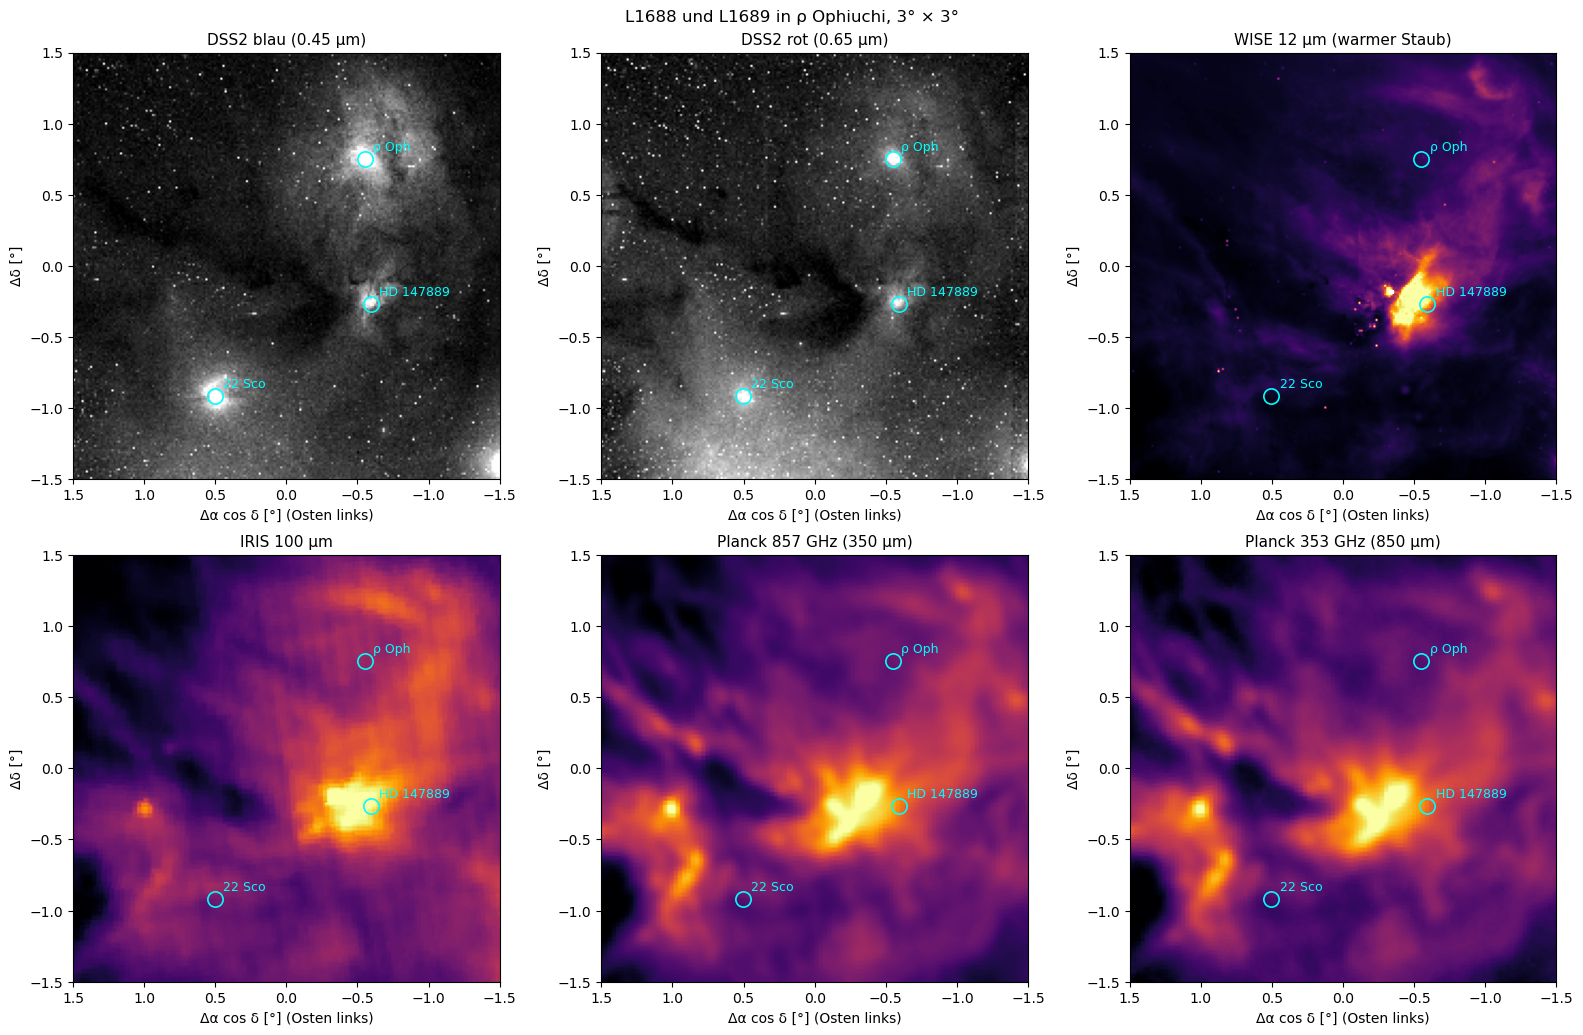

DSS2 Blue     : Median   3935.000, 99.5. Perzentil  11380.015
DSS2 Red      : Median   4494.000, 99.5. Perzentil   9822.080
WISE 12       : Median    924.137, 99.5. Perzentil   2425.351
IRIS100       : Median    118.321, 99.5. Perzentil   1773.666
Planck 857 I  : Median     57.783, 99.5. Perzentil    529.467
Planck 353 I  : Median      0.017, 99.5. Perzentil      0.166


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, (s, title) in zip(axes.flat, SURVEYS.items()):
    img = IMG[s][0]
    if s in ("WISE 12", "IRIS100", "Planck 857 I", "Planck 353 I"):
        img = np.log10(np.clip(img, np.nanpercentile(img, 0.5), None))
    lo, hi = np.nanpercentile(img, [1, 99.5])
    ax.imshow(np.clip((img - lo) / (hi - lo), 0, 1), origin="lower", cmap="gray" if "DSS" in s else "inferno",
              extent=EXT_MAP)
    for name, (ra, dec) in STARS.items():
        x, y = offsets(ra, dec)
        ax.plot(x, y, "o", mfc="none", mec="cyan", ms=11, mew=1.2)
        ax.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points", color="cyan", fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Δα cos δ [°] (Osten links)")
    ax.set_ylabel("Δδ [°]")
fig.suptitle("L1688 und L1689 in ρ Ophiuchi, 3° × 3°", fontsize=12)
plt.tight_layout()
plt.show()
for s in SURVEYS:
    v = IMG[s][0]
    print(f"{s:14s}: Median {np.nanmedian(v):10.3f}, 99.5. Perzentil {np.nanpercentile(v, 99.5):10.3f}")

* Sechs Karten desselben Feldes, Norden oben, Osten links; die Achsen geben den Abstand von der Feldmitte in Grad, ein Grad sind in 131 pc Entfernung 2.3 pc. Oben die Palomar-Platten in Blau und Rot und WISE bei 12 µm, unten die Wärmestrahlung des Staubs bei 100 µm, 350 µm und 850 µm.
* Im Blauen ist die Wolke ein dunkles Band von Westen nach Osten mit vielen fehlenden Sternen; um ρ Oph, 22 Sco und HD 147889 leuchten blaue Reflexionsnebel, die im Roten schwächer sind: Der Staub streut blaues Licht stärker. Bei 12 µm leuchtet fast nur die Umgebung von HD 147889 und einzelne junge Sterne, also Staub, den ein heißer Stern direkt bestrahlt.
* Im fernen Infrarot ist die Wolke hell statt dunkel, und das Bild ändert sich mit der Wellenlänge: Bei 100 µm liegt das Maximum auf HD 147889 (warmer Staub strahlt kurzwellig), bei 850 µm im dichten Kern östlich daneben (kalter Staub strahlt langwellig, dort ist am meisten Masse). Die Antwort auf die Vorhersage: dunkel im Blauen, hell im fernen Infraroten, und bei 12 µm leuchtet nur der Staub nahe den Sternen.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-2"></a>

##### *2. Sterne in Richtung der Wolke*

Wie viele Sterne sieht man durch die Wolke hindurch, und was verrät schon ihre bloße Zahl? Vorher vorhersagen: Sieht 2MASS im Band K in der Mitte von L1688 mehr oder weniger Sterne pro Pixel als am Rand des Feldes, und gilt das für Gaia genauso?

Der Code zählt die Sterne von 2MASS (Qualität A bis C in H und K, keine Artefakte, Fehler unter 0.1 mag) und von Gaia (Parallaxe S/N > 5) pro Pixel von 3′ × 3′ und vergleicht die Dichte mit der Planck-Karte. Dasselbe für das Kontrollfeld gibt die Zahl ohne Wolke.

**Hintergrund & Fachbegriffe:**
- **Sternzählungen:** die älteste Methode, Extinktion zu messen (Wolf 1923): Hinter einer Wolke sieht man bis zu einer Grenzhelligkeit weniger Sterne, und aus dem Defizit folgt die Extinktion. Sie braucht keine Farben, ist aber grob.
- **Qualitätsflaggen:** `ph_qual` gibt für J, H, K die Güte der Photometrie (A = S/N > 10, B > 7, C > 5); `cc_flg` markiert Artefakte wie Beugungsspitzen oder Geisterbilder heller Sterne (0 = sauber).

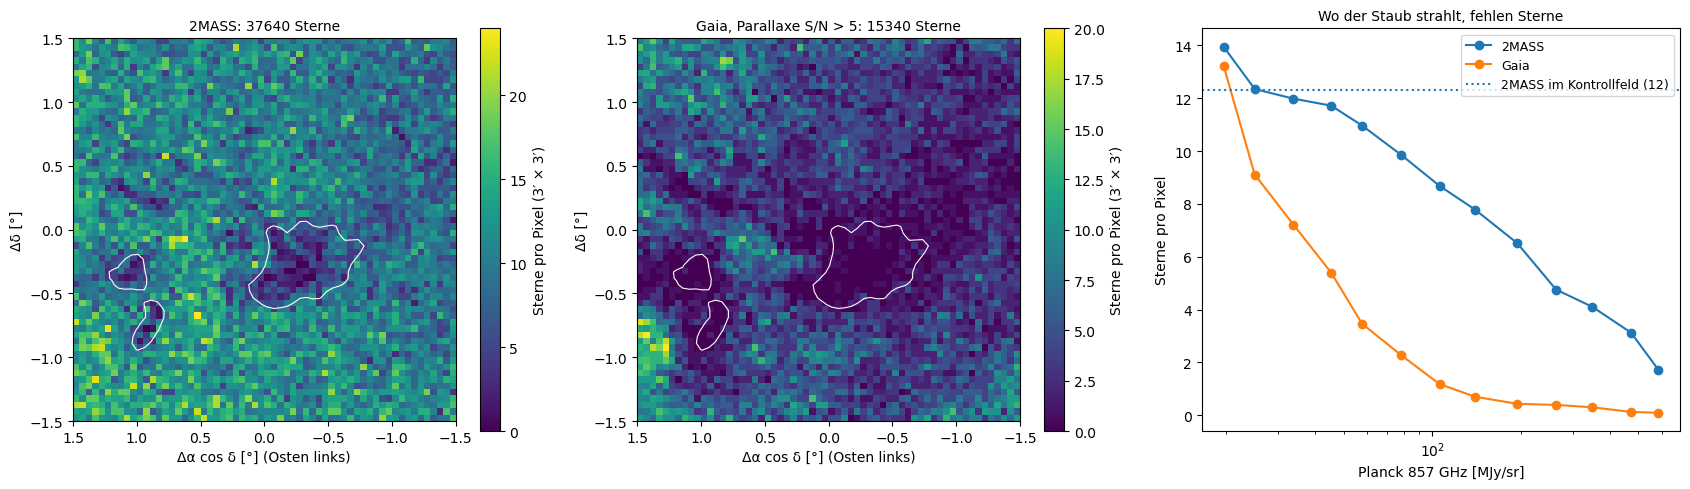

2MASS nach Qualitätsschnitt: 37640 von 102443 im Feld, 15489 von 51321 im Kontrollfeld; mit J: 96%
Sterne pro Pixel: 2MASS Median 10 (Kontrollfeld 12.3), leere Pixel 10; Gaia Median 3, leere Pixel 460
In den 5 % hellsten Planck-Pixeln: 2MASS 4.9, Gaia 0.3 Sterne pro Pixel


In [4]:
def clean_2mass(t):
    q, c = t["ph_qual"].astype(str), t["cc_flg"].astype(str)
    ok = q.str[1].isin(list("ABC")) & q.str[2].isin(list("ABC")) & (c.str[1:3] == "00")
    ok &= (t["h_msigcom"] < 0.1) & (t["k_msigcom"] < 0.1)
    t = t[ok].copy()
    t["has_j"] = t["ph_qual"].astype(str).str[0].isin(list("ABC")) & (t["j_msigcom"] < 0.1) & (t["cc_flg"].astype(str).str[0] == "0")
    t["jh"], t["hk"] = t["j_m"] - t["h_m"], t["h_m"] - t["k_m"]
    return t


STARS2M, CTRL2M = clean_2mass(TM), clean_2mass(TM_CTRL)
_, N2M = to_map(STARS2M["ra"], STARS2M["dec"], np.zeros(len(STARS2M)), min_n=0)
_, NGA = to_map(GAIA["ra"], GAIA["dec"], np.zeros(len(GAIA)), min_n=0)
ctrl_area = np.pi * CTRL[2] ** 2 * 3600 / 9                        # Pixel von 3′ × 3′ im Kontrollfeld
dens_ctrl = len(CTRL2M) / ctrl_area

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (m, title) in zip(axes[:2], [(N2M, f"2MASS: {len(STARS2M)} Sterne"), (NGA, f"Gaia, Parallaxe S/N > 5: {len(GAIA)} Sterne")]):
    im = ax.imshow(m, origin="lower", cmap="viridis", extent=EXT_MAP)
    plt.colorbar(im, ax=ax, label="Sterne pro Pixel (3′ × 3′)")
    ax.contour(np.log10(GRID["Planck 857 I"]), levels=[2.2], colors="w", linewidths=0.8, extent=EXT_MAP)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Δα cos δ [°] (Osten links)")
    ax.set_ylabel("Δδ [°]")
ax = axes[2]
I857 = GRID["Planck 857 I"]
for m, col, lab in [(N2M, "C0", "2MASS"), (NGA, "C1", "Gaia")]:
    bins = np.logspace(np.log10(I857.min()), np.log10(I857.max()), 15)
    idx = np.digitize(I857.ravel(), bins)
    xs = [np.median(I857.ravel()[idx == k]) for k in range(1, len(bins)) if (idx == k).sum() > 5]
    ys = [np.mean(m.ravel()[idx == k]) for k in range(1, len(bins)) if (idx == k).sum() > 5]
    ax.plot(xs, ys, "o-", color=col, label=lab)
ax.axhline(dens_ctrl, color="C0", ls=":", label=f"2MASS im Kontrollfeld ({dens_ctrl:.0f})")
ax.set_xscale("log")
ax.set_xlabel("Planck 857 GHz [MJy/sr]")
ax.set_ylabel("Sterne pro Pixel")
ax.set_title("Wo der Staub strahlt, fehlen Sterne", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"2MASS nach Qualitätsschnitt: {len(STARS2M)} von {len(TM)} im Feld, {len(CTRL2M)} von {len(TM_CTRL)} im Kontrollfeld; "
      f"mit J: {STARS2M['has_j'].mean():.0%}")
print(f"Sterne pro Pixel: 2MASS Median {np.median(N2M):.0f} (Kontrollfeld {dens_ctrl:.1f}), leere Pixel {np.sum(N2M == 0)}; "
      f"Gaia Median {np.median(NGA):.0f}, leere Pixel {np.sum(NGA == 0)}")
hi857 = I857 > np.percentile(I857, 95)
print(f"In den 5 % hellsten Planck-Pixeln: 2MASS {N2M[hi857].mean():.1f}, Gaia {NGA[hi857].mean():.1f} Sterne pro Pixel")

* Links und Mitte die Zahl der Sterne pro Pixel von 3′ × 3′, die weiße Linie umrandet die hellsten Teile der Planck-Karte. 2MASS zählt im Median 10 Sterne pro Pixel (Kontrollfeld 12.3) und nur 10 leere Pixel; Gaia mit guter Parallaxe zählt 3 und hat 460 leere Pixel.
* Rechts die Sterndichte gegen die Helligkeit bei 857 GHz: Je mehr Staub strahlt, desto weniger Sterne kommen durch. In den 5 % hellsten Planck-Pixeln sieht 2MASS noch 4.9 Sterne pro Pixel, Gaia 0.3. Wie vorhergesagt fehlen in der Mitte von L1688 Sterne, bei Gaia viel stärker, weil die Extinktion im Optischen zehnmal größer ist als im Band K.
* Damit ist auch klar, wofür welche Daten taugen: 2MASS für die Extinktionskarte, Gaia nur für den Rand der Wolke und für die Sterne davor.

[↑ Zurück zur Landkarte](#landkarte)

#### **Reduktion**

<a id="exp-3"></a>

##### *3. Farben ohne und mit Staub*

Welche Farben haben die Sterne ohne Staub, und wie verschiebt die Wolke sie? Vorher vorhersagen: In welche Richtung im Diagramm J−H gegen H−K wandert ein Stern, wenn Staub vor ihm liegt, und wie steil?

Im Kontrollfeld (E(B−V) = 0.14 nach Schlafly & Finkbeiner) zeigen die Sterne ihre Eigenfarben: Hauptreihensterne und Riesen bilden eine schmale Wolke bei H−K ≈ 0.1 und J−H ≈ 0.5. Der Code bestimmt Median und Streuung und zieht die kleine Rötung des Kontrollfelds ab. Im Feld der Wolke sind dieselben Sterne entlang des Rötungsvektors verschoben; die Länge der Verschiebung ist die Extinktion.

**Hintergrund & Fachbegriffe:**
- **Farb-Farb-Diagramm:** zwei Farben gegeneinander; Sterne verschiedener Temperatur liegen auf einer Kurve, Staub verschiebt sie alle in dieselbe Richtung.
- **Rötungsvektor:** die Verschiebung durch A_V = 1 mag: E(J−H) = A_J − A_H = 0.107 mag und E(H−K) = A_H − A_K = 0.063 mag (Rieke & Lebofsky 1985), Steigung 1.70.
- **Infrarotexzess:** Junge Sterne mit einer Scheibe aus warmem Staub sind in K heller; sie liegen rechts vom Rötungsband und täuschen zu viel Extinktion vor.

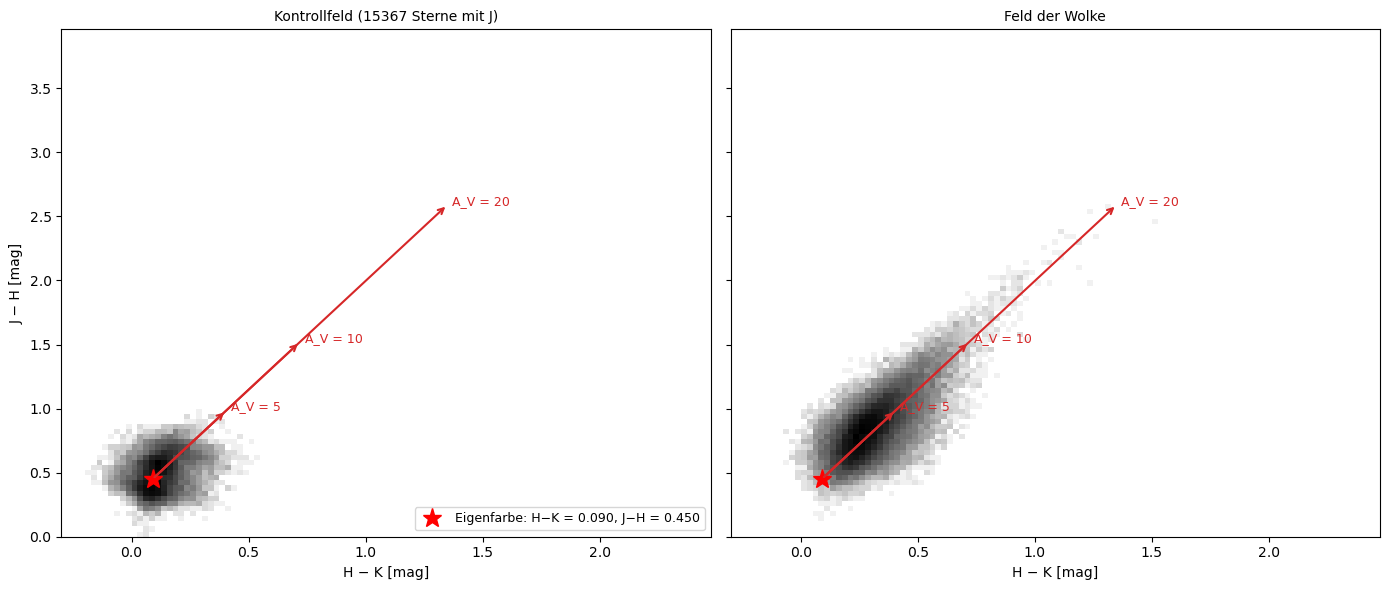

Kontrollfeld: H−K Median 0.117, J−H Median 0.497; abzüglich A_V = 0.43: H−K₀ = 0.090 ± 0.073, J−H₀ = 0.450 ± 0.156 (Streuung)
Streuung in A_V pro Stern aus der Eigenfarbe: H−K 1.15 mag, J−H 1.45 mag


In [5]:
k_hk, k_jh = 1 / (R_JHK["H"] - R_JHK["K"]), 1 / (R_JHK["J"] - R_JHK["H"])
av_ctrl = 3.1 * EBV_CTRL
cj = CTRL2M[CTRL2M["has_j"]]
HK0 = CTRL2M["hk"].median() - av_ctrl / k_hk                         # Eigenfarben ohne Staub
JH0 = cj["jh"].median() - av_ctrl / k_jh
SIG_HK = 1.4826 * np.median(np.abs(CTRL2M["hk"] - CTRL2M["hk"].median()))
SIG_JH = 1.4826 * np.median(np.abs(cj["jh"] - cj["jh"].median()))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, (df, title) in zip(axes, [(cj, f"Kontrollfeld ({len(cj)} Sterne mit J)"), (STARS2M[STARS2M["has_j"]], "Feld der Wolke")]):
    ax.hist2d(df["hk"], df["jh"], bins=[np.arange(-0.3, 2.5, 0.025), np.arange(0, 4.0, 0.04)], cmap="Greys", cmin=1,
              norm=plt.matplotlib.colors.LogNorm())
    ax.plot(HK0, JH0, "r*", ms=14, label=f"Eigenfarbe: H−K = {HK0:.3f}, J−H = {JH0:.3f}")
    for av in (5, 10, 20):
        ax.annotate("", xy=(HK0 + av / k_hk, JH0 + av / k_jh), xytext=(HK0, JH0),
                    arrowprops=dict(arrowstyle="->", color="C3", lw=1.5))
        ax.text(HK0 + av / k_hk + 0.02, JH0 + av / k_jh, f"A_V = {av}", color="C3", fontsize=9)
    ax.set_xlabel("H − K [mag]")
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("J − H [mag]")
axes[0].legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

print(f"Kontrollfeld: H−K Median {CTRL2M['hk'].median():.3f}, J−H Median {cj['jh'].median():.3f}; "
      f"abzüglich A_V = {av_ctrl:.2f}: H−K₀ = {HK0:.3f} ± {SIG_HK:.3f}, J−H₀ = {JH0:.3f} ± {SIG_JH:.3f} (Streuung)")
print(f"Streuung in A_V pro Stern aus der Eigenfarbe: H−K {k_hk * SIG_HK:.2f} mag, J−H {k_jh * SIG_JH:.2f} mag")

* Links das Kontrollfeld: Die Sterne bilden eine Wolke bei H−K ≈ 0.1 und J−H ≈ 0.5. Nach Abzug der kleinen Rötung dort (A_V = 0.43) sind die Eigenfarben (H−K)₀ = 0.090 ± 0.073 und (J−H)₀ = 0.450 ± 0.156; die Streuung kommt von verschiedenen Sterntypen und Messfehlern.
* Rechts das Feld der Wolke: Dieselbe Sternwolke ist entlang des roten Pfeils nach rechts oben gezogen, zu J−H bis über 2.5 und H−K bis 1.5. Das ist die Antwort auf die Vorhersage: Staub schiebt jeden Stern entlang des Rötungsvektors mit Steigung 1.70 nach rechts oben, um so weiter, je mehr Staub vor ihm liegt.
* Aus der Streuung der Eigenfarben folgt der Fehler pro Stern: 1.15 mag in A_V aus H−K und 1.45 mag aus J−H. Erst der Median vieler Sterne macht die Karte genau.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-4"></a>

##### *4. Die Extinktionskarte*

Wie viel Staub liegt in jeder Richtung, gemessen an den Sternen dahinter? Vorher vorhersagen: Wie groß wird A_V in der Mitte von L1688 ungefähr, wenn dort Sterne mit H−K ≈ 1.5 zu sehen sind?

Für jeden Stern gibt die Farbe zwei Schätzungen der Extinktion: A_V = 15.9 · (H−K − (H−K)₀) und, wenn J gemessen ist, A_V = 9.3 · (J−H − (J−H)₀). Gemittelt werden sie mit Gewichten aus Messfehler und Streuung der Eigenfarben (eine vereinfachte Form der Methode NICER, Lombardi & Alves 2001). Pro Pixel von 3′ zählt der Median aller Sterne, wenn es mindestens drei sind. Links die Karte, rechts der Vergleich mit Planck 857 GHz Pixel für Pixel.

**Hintergrund & Fachbegriffe:**
- **NICER:** Near-Infrared Color Excess Revisited; kombiniert beide Farben optimal und berücksichtigt die Streuung der Eigenfarben. Die ältere Methode NICE (Lada et al. 1994) benutzt nur H−K.
- **Median pro Pixel:** robust gegen einzelne junge Sterne mit Infrarotexzess und gegen Vordergrundsterne ohne Extinktion.
- **Auflösung:** Ein Pixel von 3′ sind in 137 pc Entfernung 0.12 pc; dichte Kerne, kleiner als das, werden verschmiert, und hinter den dichtesten sieht 2MASS keinen Stern mehr.

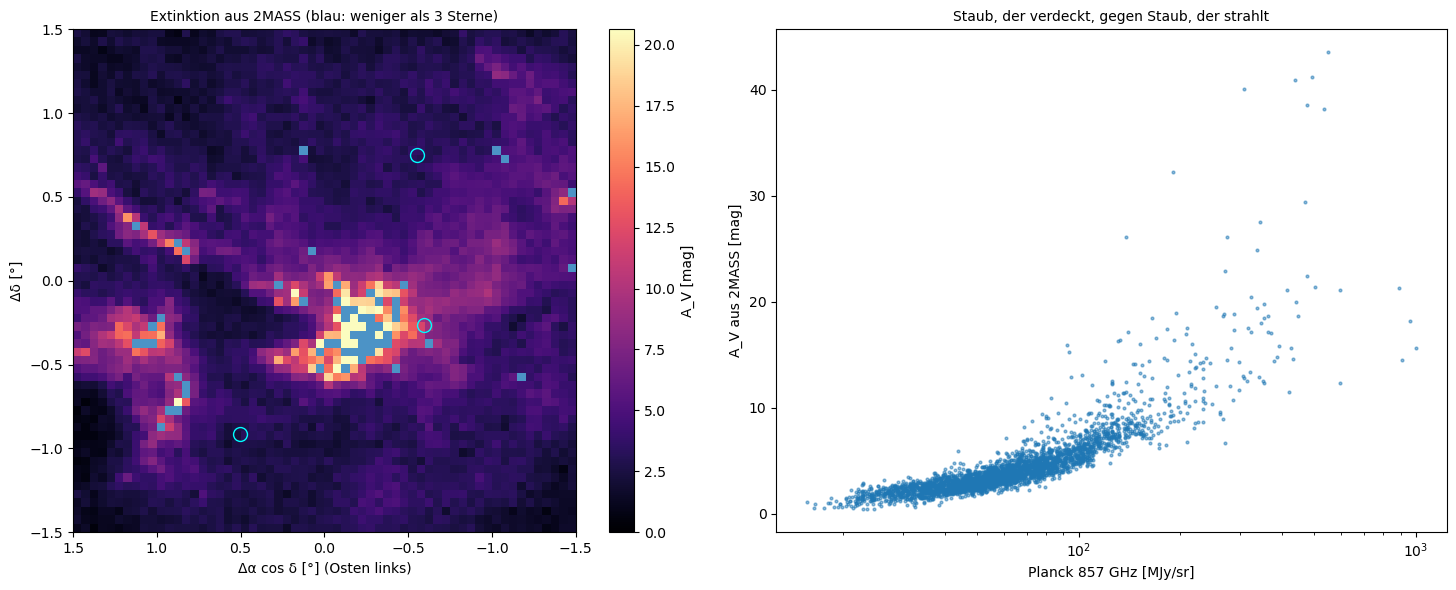

37640 Sterne, A_V pro Stern Median 3.47, Fehler pro Stern Median 1.08 mag
Karte: 3542 von 3600 Pixeln mit ≥ 3 Sternen; A_V Median 3.50, 95. Perzentil 9.2, Maximum 43.5 mag; Rangkorrelation mit Planck 857 0.91
Leere Pixel liegen bei Planck 857 im Median bei 279 MJy/sr (Feld 58)


In [6]:
def av_star(t):
    # Extinktion pro Stern aus H−K und J−H, gewichtet mit Messfehler und Streuung der Eigenfarben
    av_hk = k_hk * (t["hk"] - HK0)
    var_hk = k_hk**2 * (SIG_HK**2 + t["h_msigcom"] ** 2 + t["k_msigcom"] ** 2)
    av_jh = k_jh * (t["jh"] - JH0)
    var_jh = k_jh**2 * (SIG_JH**2 + t["j_msigcom"] ** 2 + t["h_msigcom"] ** 2)
    w_hk, w_jh = 1 / var_hk, np.where(t["has_j"], 1 / var_jh, 0.0)
    av = (w_hk * av_hk + w_jh * np.nan_to_num(av_jh)) / (w_hk + w_jh)
    return av, 1 / np.sqrt(w_hk + w_jh)


STARS2M["AV"], STARS2M["AV_err"] = av_star(STARS2M)
AV_MAP, N_MAP = to_map(STARS2M["ra"], STARS2M["dec"], STARS2M["AV"])
good = np.isfinite(AV_MAP)
logI = np.log10(GRID["Planck 857 I"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
im = ax.imshow(AV_MAP, origin="lower", cmap="magma", extent=EXT_MAP, vmin=0, vmax=np.nanpercentile(AV_MAP, 99.5))
plt.colorbar(im, ax=ax, label="A_V [mag]")
ax.imshow(np.where(good, np.nan, 1.0), origin="lower", cmap="Blues", vmin=0, vmax=1.5, extent=EXT_MAP, alpha=0.9)
for name, (ra, dec) in STARS.items():
    x, y = offsets(ra, dec)
    ax.plot(x, y, "o", mfc="none", mec="cyan", ms=10)
ax.set_title(f"Extinktion aus 2MASS (blau: weniger als {MIN_STARS} Sterne)", fontsize=10)
ax.set_xlabel("Δα cos δ [°] (Osten links)")
ax.set_ylabel("Δδ [°]")
ax = axes[1]
ax.scatter(GRID["Planck 857 I"][good], AV_MAP[good], s=4, alpha=0.5)
ax.set_xscale("log")
ax.set_xlabel("Planck 857 GHz [MJy/sr]")
ax.set_ylabel("A_V aus 2MASS [mag]")
ax.set_title("Staub, der verdeckt, gegen Staub, der strahlt", fontsize=10)
plt.tight_layout()
plt.show()

rho = stats.spearmanr(GRID["Planck 857 I"][good], AV_MAP[good]).statistic
print(f"{len(STARS2M)} Sterne, A_V pro Stern Median {STARS2M['AV'].median():.2f}, Fehler pro Stern Median {STARS2M['AV_err'].median():.2f} mag")
print(f"Karte: {good.sum()} von {good.size} Pixeln mit ≥ {MIN_STARS} Sternen; A_V Median {np.nanmedian(AV_MAP):.2f}, "
      f"95. Perzentil {np.nanpercentile(AV_MAP, 95):.1f}, Maximum {np.nanmax(AV_MAP):.1f} mag; Rangkorrelation mit Planck 857 {rho:.2f}")
print(f"Leere Pixel liegen bei Planck 857 im Median bei {np.median(GRID['Planck 857 I'][~good]):.0f} MJy/sr "
      f"(Feld {np.median(GRID['Planck 857 I']):.0f})")

* Links die Karte der Extinktion: Median A_V = 3.5 mag, 95 % der Pixel unter 9.2 mag, im Kern von L1688 über 20 mag (Maximum 43.5 mag). Blau sind die Pixel mit weniger als drei Sternen; sie liegen genau im dichtesten Kern, wo die Planck-Strahlung im Median 279 MJy/sr beträgt statt 58 im ganzen Feld.
* Rechts A_V gegen Planck 857 GHz: Die Rangkorrelation ist 0.91, Staub, der verdeckt, und Staub, der strahlt, sind derselbe. Die Streuung wächst nach oben, weil in dichten Pixeln nur wenige Sterne den Median bilden.
* Zur Vorhersage: H−K = 1.5 gibt A_V = 15.9 × (1.5 − 0.09) ≈ 22 mag. Im Optischen wären das 10⁹-fach weniger Licht; im Band K nur 2.5 mag.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung**

<a id="exp-5"></a>

##### *5. Rötung gegen Entfernung*

Ab welcher Entfernung werden die Sterne in Richtung der Wolke plötzlich rot? Vorher vorhersagen: Wie groß ist A_G für Sterne vor der Wolke, und wie groß dahinter, wenn die Karte aus Schritt 4 dort A_V ≈ 5 bis 10 zeigt?

Gaia schätzt für jeden Stern die Extinktion A_G aus seinem BP/RP-Spektrum; die Entfernung kommt aus der Parallaxe (mit dem Nullpunkt −0.017 mas). Der Code teilt die Sterne in zwei Gruppen: auf der Wolke (Pixel mit A_V > 5 in der Karte aus Schritt 4 oder ohne Wert, weil zu dicht) und daneben (A_V < 2). Links A_G gegen Entfernung für beide Gruppen, rechts der Median in Entfernungsintervallen.

**Hintergrund & Fachbegriffe:**
- **A_G:** Extinktion im breiten Gaia-Band G (330 bis 1050 nm); für gewöhnliche Sterne ist A_G ≈ 0.8 · A_V.
- **Dünne Wolke:** Liegt fast der ganze Staub in einer Schicht von wenigen Parsec, springt die Extinktion an ihrer Entfernung von fast null auf einen hohen Wert; davor liegen nur wenige Sterne, dahinter viele (Theorie, Abschnitt 5).
- **Grenze von Gaia:** Hinter sehr viel Staub ist ein Stern im Optischen zu schwach für eine Parallaxe; Gaia sieht deshalb nur den Rand der dichten Kerne.

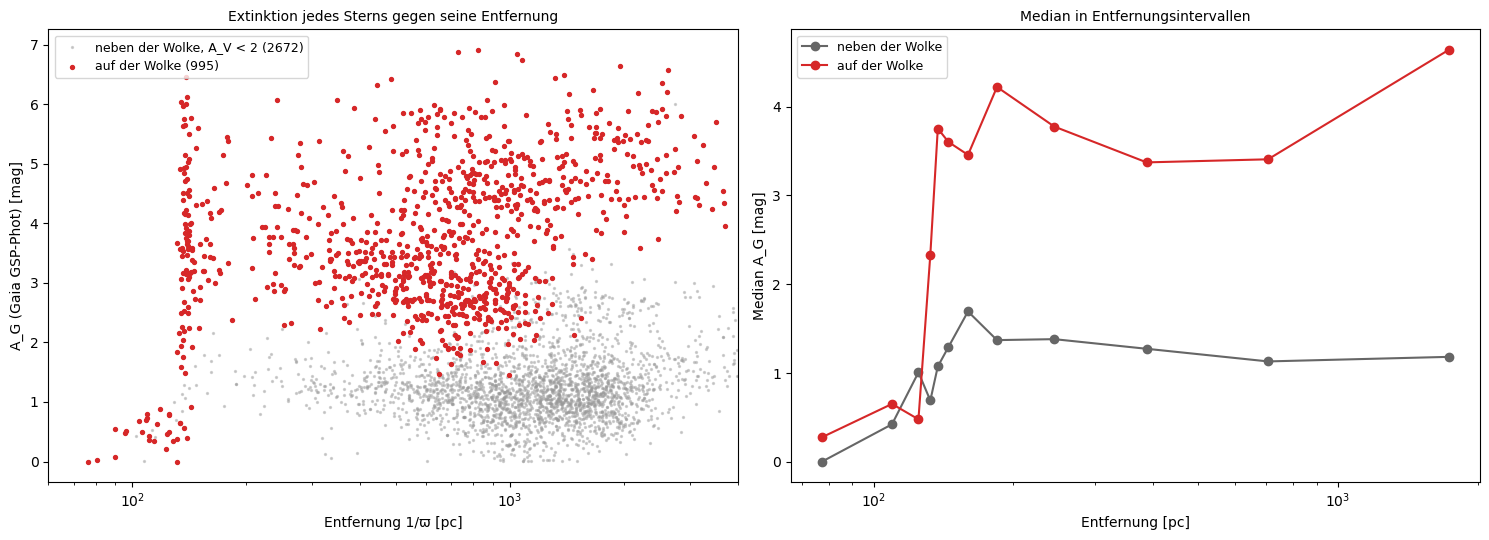

             auf der Wolke (Zahl: A_G) daneben (Zahl: A_G)
d                                                         
(0, 100]                       6: 0.28             1: 0.00
(100, 120]                    10: 0.65             5: 0.42
(120, 130]                     6: 0.48             1: 1.01
(130, 135]                    14: 2.33             1: 0.69
(135, 140]                    43: 3.75             5: 1.07
(140, 150]                    34: 3.60             3: 1.29
(150, 170]                    19: 3.46             5: 1.69
(170, 200]                     9: 4.22             6: 1.37
(200, 300]                    53: 3.77            40: 1.38
(300, 500]                   128: 3.37           158: 1.27
(500, 1000]                  426: 3.41           736: 1.13
(1000, 3000]                 231: 4.64          1604: 1.18


In [7]:
GAIA["d"] = 1000 / (GAIA["parallax"] + 0.017)
GAIA["plx"] = GAIA["parallax"] + 0.017
GAIA["AV_map"] = at_map(AV_MAP, GAIA["ra"], GAIA["dec"])
xi, yi, ok = pixel_of(GAIA["ra"], GAIA["dec"])
GAIA["in_field"] = ok
GAIA["empty"] = ok & np.isnan(GAIA["AV_map"])
on = GAIA["in_field"] & ((GAIA["AV_map"] > AV_CLOUD) | GAIA["empty"])
off = GAIA["in_field"] & (GAIA["AV_map"] < 2)
EDGES = [0, 100, 120, 130, 135, 140, 150, 170, 200, 300, 500, 1000, 3000]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.scatter(GAIA.loc[off, "d"], GAIA.loc[off, "ag_gspphot"], s=2, c="0.6", alpha=0.4, label=f"neben der Wolke, A_V < 2 ({off.sum()})")
ax.scatter(GAIA.loc[on, "d"], GAIA.loc[on, "ag_gspphot"], s=8, c="C3", label=f"auf der Wolke ({on.sum()})")
ax.set_xscale("log")
ax.set_xlim(60, 4000)
ax.set_xlabel("Entfernung 1/ϖ [pc]")
ax.set_ylabel("A_G (Gaia GSP-Phot) [mag]")
ax.set_title("Extinktion jedes Sterns gegen seine Entfernung", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
for m, col, lab in [(off, "0.4", "neben der Wolke"), (on, "C3", "auf der Wolke")]:
    s = GAIA[m]
    g = s.groupby(pd.cut(s["d"], EDGES), observed=False)["ag_gspphot"]
    mid = [np.sqrt(max(a.left, 60) * a.right) for a in g.median().index]
    ax.plot(mid, g.median().values, "o-", color=col, label=lab)
ax.set_xscale("log")
ax.set_xlabel("Entfernung [pc]")
ax.set_ylabel("Median A_G [mag]")
ax.set_title("Median in Entfernungsintervallen", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

table = pd.DataFrame({lab: GAIA[m].groupby(pd.cut(GAIA.loc[m, "d"], EDGES), observed=False)["ag_gspphot"].agg(["count", "median"])
                      .apply(lambda r: f"{int(r['count'])}: {r['median']:.2f}" if r["count"] else "–", axis=1)
                      for m, lab in [(on, "auf der Wolke (Zahl: A_G)"), (off, "daneben (Zahl: A_G)")]})
print(table.to_string())

* Links jeder Gaia-Stern mit seiner Extinktion A_G und Entfernung, rot auf der Wolke (A_V > 5 oder Pixel ohne Wert), grau daneben (A_V < 2). Bis 130 pc haben auch die Sterne auf der Wolke fast keine Extinktion; zwischen 130 und 140 pc steigt sie auf einer senkrechten Wand auf 3 bis 6 mag. Dort stehen 57 Sterne, viele davon die jungen Sterne der Wolke selbst.
* Rechts die Mediane: auf der Wolke 0.3 bis 0.65 mag bis 130 pc, 2.3 mag zwischen 130 und 135 pc und 3.4 bis 4.6 mag dahinter; daneben steigt A_G nur auf 1.1 bis 1.4 mag, den Staub der Ausläufer.
* Zur Vorhersage: Vor der Wolke ist A_G ≈ 0.5 mag; dahinter erwartet man bei A_V = 5 bis 10 etwa A_G = 4 bis 8, gemessen sind im Median 3.4 bis 3.8. Gaia sieht hinter dem Staub nur die Sterne, die noch hell genug sind, also die mit weniger Extinktion; die stärker geröteten fehlen.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-6"></a>

##### *6. Wie warm ist der Staub?*

Welche Temperatur hat der Staub, und wo ist er besonders kalt oder warm? Vorher vorhersagen: Ist der Staub in den dichtesten Teilen der Wolke wärmer oder kälter als in ihrer Umgebung?

In jedem Pixel von 3′ passt der Code einen modifizierten Schwarzkörper an die vier Bänder IRIS 100 µm und Planck 857, 545 und 353 GHz an, mit drei freien Größen: optische Tiefe τ353, Temperatur T und Spektralindex β (Theorie, Abschnitt 4). Als Fehler gelten 10 % pro Band. Oben stehen drei Beispiel-Spektren (ein dichter Kern, die Umgebung von HD 147889 und ein Pixel am Feldrand), unten die Karten von T und τ353.

**Hintergrund & Fachbegriffe:**
- **Modifizierter Schwarzkörper:** I_ν = τ353 (ν / 353 GHz)^β B_ν(T). Staubkörner sind viel kleiner als die Wellenlänge; ihr Emissionsvermögen fällt deshalb mit ν^β, β ≈ 1.5 bis 2.
- **Optische Tiefe τ353:** der Bruchteil der Strahlung bei 353 GHz, den die Staubsäule absorbieren würde; in Wolken nur 10⁻⁴ bis 10⁻³, die Wolke ist im fernen Infrarot also durchsichtig, und τ ist proportional zur Menge Staub.
- **Wiensches Gesetz:** Ein Körper von 20 K strahlt am stärksten bei etwa 150 µm (2000 GHz), zwischen IRIS und Planck 857.

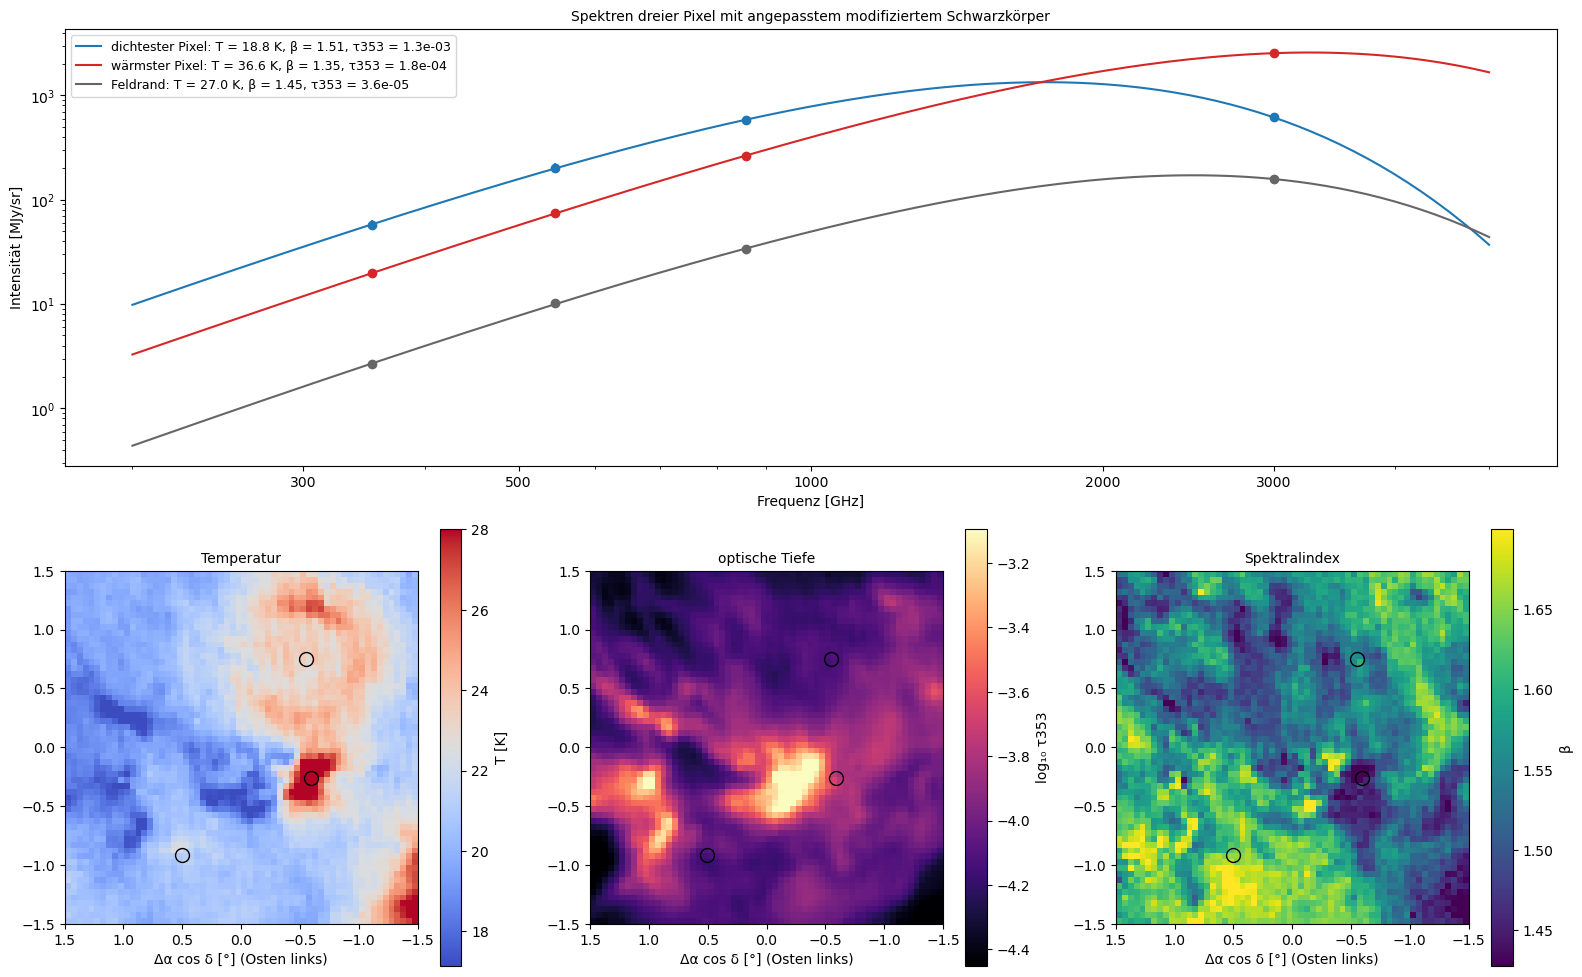

T: Median 20.8 K (5 % bis 95 %: 18.3 bis 24.8), β: Median 1.56 (1.46 bis 1.67); mit β = 1.6: T Median 20.7 K
In den 5 % dichtesten Pixeln: T 18.3 K, sonst 20.9 K; Rangkorrelation T–β -0.25
dichtester Pixel: Δ = (-0.23°, -0.32°), T = 18.8 K, β = 1.51, τ353 = 1.31e-03
wärmster Pixel  : Δ = (-0.58°, -0.22°), T = 36.6 K, β = 1.35, τ353 = 1.80e-04
Feldrand        : Δ = (-1.34°, -1.32°), T = 27.0 K, β = 1.45, τ353 = 3.62e-05


In [8]:
TAU, TEMP, BETA = (np.full((NPIX_MAP, NPIX_MAP), np.nan) for _ in range(3))
TEMP_FIX = np.full((NPIX_MAP, NPIX_MAP), np.nan)
for i in range(NPIX_MAP):
    for j in range(NPIX_MAP):
        TAU[i, j], TEMP[i, j], BETA[i, j] = fit_sed(SED[:, i, j])
        TEMP_FIX[i, j] = fit_sed(SED[:, i, j], beta=BETA_FIX)[1]
core = np.unravel_index(np.argmax(TAU), TAU.shape)
hot = np.unravel_index(np.argmax(TEMP), TEMP.shape)
edge = (3, NPIX_MAP - 4)
EXAMPLES = {"dichtester Pixel": core, "wärmster Pixel": hot, "Feldrand": edge}

fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(2, 3, (1, 3))
nu_plot = np.logspace(np.log10(200e9), np.log10(5e12), 200)
for (lab, (i, j)), col in zip(EXAMPLES.items(), ["C0", "C3", "0.4"]):
    ax.errorbar(NU / 1e9, SED[:, i, j], yerr=SED_ERR * SED[:, i, j], fmt="o", color=col)
    ax.plot(nu_plot / 1e9, mbb(nu_plot, TAU[i, j], TEMP[i, j], BETA[i, j]), color=col,
            label=f"{lab}: T = {TEMP[i, j]:.1f} K, β = {BETA[i, j]:.2f}, τ353 = {TAU[i, j]:.1e}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([300, 500, 1000, 2000, 3000], labels=["300", "500", "1000", "2000", "3000"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("Frequenz [GHz]")
ax.set_ylabel("Intensität [MJy/sr]")
ax.set_title("Spektren dreier Pixel mit angepasstem modifiziertem Schwarzkörper", fontsize=10)
ax.legend(fontsize=9)
for k, (m, title, cmap, lab) in enumerate([(TEMP, "Temperatur", "coolwarm", "T [K]"),
                                           (np.log10(TAU), "optische Tiefe", "magma", "log₁₀ τ353"),
                                           (BETA, "Spektralindex", "viridis", "β")]):
    ax = fig.add_subplot(2, 3, 4 + k)
    lo, hi = np.percentile(m, [1, 99])
    im = ax.imshow(m, origin="lower", cmap=cmap, extent=EXT_MAP, vmin=lo, vmax=hi)
    plt.colorbar(im, ax=ax, label=lab)
    for name, (ra, dec) in STARS.items():
        x, y = offsets(ra, dec)
        ax.plot(x, y, "o", mfc="none", mec="k", ms=10)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Δα cos δ [°] (Osten links)")
plt.tight_layout()
plt.show()

dense = TAU > np.percentile(TAU, 95)
print(f"T: Median {np.median(TEMP):.1f} K (5 % bis 95 %: {np.percentile(TEMP, 5):.1f} bis {np.percentile(TEMP, 95):.1f}), "
      f"β: Median {np.median(BETA):.2f} ({np.percentile(BETA, 5):.2f} bis {np.percentile(BETA, 95):.2f}); "
      f"mit β = {BETA_FIX}: T Median {np.median(TEMP_FIX):.1f} K")
print(f"In den 5 % dichtesten Pixeln: T {np.median(TEMP[dense]):.1f} K, sonst {np.median(TEMP[~dense]):.1f} K; "
      f"Rangkorrelation T–β {stats.spearmanr(TEMP.ravel(), BETA.ravel()).statistic:+.2f}")
for lab, (i, j) in EXAMPLES.items():
    ox, oy = offsets(RA_MAP[i, j], DE_MAP[i, j])
    print(f"{lab:16s}: Δ = ({ox:+.2f}°, {oy:+.2f}°), "
          f"T = {TEMP[i, j]:.1f} K, β = {BETA[i, j]:.2f}, τ353 = {TAU[i, j]:.2e}")

* Oben drei Spektren mit dem angepassten modifizierten Schwarzkörper: Der dichteste Pixel (τ353 = 1.3·10⁻³) ist mit 18.8 K am kältesten und hat sein Maximum bei niedriger Frequenz; der wärmste (36.6 K, 3′ neben HD 147889) strahlt am stärksten bei 100 µm; der Feldrand im Südwesten hat wenig Staub (τ353 = 3.6·10⁻⁵), aber 27 K.
* Unten die Karten: Im Median ist der Staub 20.8 K warm (5 % bis 95 %: 18.3 bis 24.8 K) mit β = 1.56; mit festem β = 1.6 sind es 20.7 K. Die 5 % dichtesten Pixel haben 18.3 K, der Rest 20.9 K. Wie vorhergesagt ist dichter Staub kälter: Das Licht der Sterne dringt nicht ein.
* Warm sind die Umgebung von HD 147889, ein Bogen um ρ Oph im Norden und die Südwestecke. Vermutlich heizt dort σ Sco, ein B1-Riese knapp außerhalb des Feldes. Die schwache Gegenläufigkeit von T und β (Rangkorrelation −0.25) ist zum Teil echt, zum Teil ein bekannter Effekt des Fits: Ein steileres β und eine niedrigere T beschreiben vier Punkte ähnlich gut.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-7"></a>

##### *7. Ein Stern heizt den Staub*

Warum ist der Staub um HD 147889 so warm, und folgt seine Temperatur dem Gesetz, das man für einen einzelnen heizenden Stern erwartet? Vorher vorhersagen: Wenn ein Staubkorn zehnmal weiter vom Stern entfernt ist, um welchen Faktor sinkt die Heizleistung, und um welchen die Temperatur?

HD 147889 ist ein Stern vom Typ B2 in 136 pc Entfernung, am Rand von L1688 und von Staub umgeben; das Licht, das der Staub nahe dem Stern streut, ist der Reflexionsnebel. Der Code nimmt die Temperatur (mit β = 1.6 fest, damit T und β sich nicht gegenseitig vertreten) als Funktion des Abstands vom Stern und passt das Modell T^(4+β) = T_b^(4+β) · (1 + (r₀/r)^n) an: eine gleichmäßige Heizung durch das Licht aller Sterne der Milchstraße (T_b, aus dem Ring 30′ bis 40′) plus der Stern, dessen Fluss mit r^(−n) fällt (Theorie, Abschnitt 4). Pixel näher als 5′ bleiben draußen, weil der Planck-Strahl sie verschmiert.

**Hintergrund & Fachbegriffe:**
- **Strahlungsgleichgewicht:** Ein Staubkorn strahlt so viel ab, wie es absorbiert. Absorbiert es den Fluss F, gilt F ∝ T^(4+β); fällt F wie 1/r², fällt T wie r^(−2/(4+β)) ≈ r^(−0.36).
- **Interstellares Strahlungsfeld:** das gemittelte Licht aller Sterne der Milchstraße, das jeden Ort von allen Seiten erreicht; es heizt Staub fern von hellen Sternen auf 15 bis 20 K.
- **Projizierter Abstand:** Gemessen wird r am Himmel; der wahre Abstand ist größer oder gleich, je nachdem, wie weit der Staub vor oder hinter dem Stern liegt.

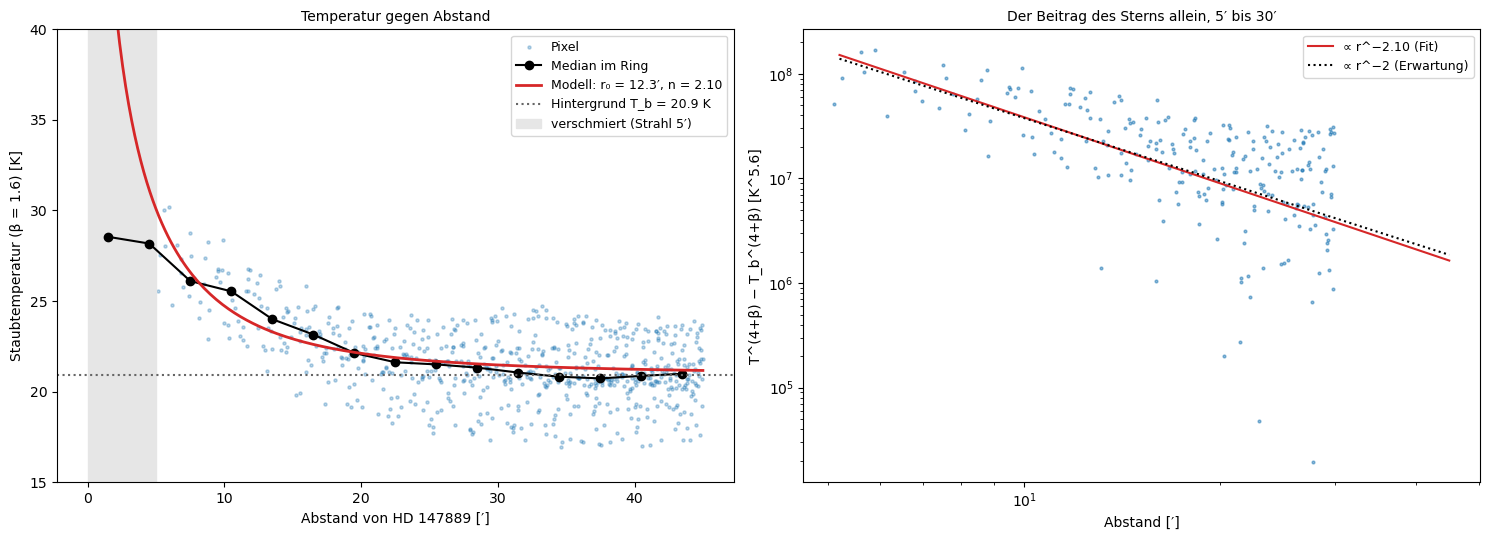

T_b = 20.93 K (Ring 30′ bis 40′); Fit 5′ bis 30′: r₀ = 12.3 ± 0.4′ (0.49 pc), n = 2.10 ± 0.13 (erwartet 2); Gerade im log-log-Bild: Steigung -1.77
Ringmediane: 0–3′ 28.5 K, 9–12′ 25.5 K, 18–21′ 22.1 K, 30–33′ 21.0 K; wärmster Pixel 31.3 K in 2.7′ Abstand


In [9]:
dx, dy = offsets(RA_MAP, DE_MAP)
sx, sy = offsets(*HD147889)
R_ARC = np.hypot(dx - sx, dy - sy) * 60                              # projizierter Abstand [′]
n_b = 4 + BETA_FIX
T_B = np.median(TEMP_FIX[(R_ARC >= 30) & (R_ARC < 40)])             # Hintergrund aus dem Ring 30′ bis 40′
fit_r = (R_ARC > 5) & (R_ARC < 30)                                   # innerhalb von 5′ verschmiert der Planck-Strahl


def heat_model(r, r0, n):
    return (T_B**n_b * (1 + (r0 / r) ** n)) ** (1 / n_b)


p, cov = optimize.curve_fit(heat_model, R_ARC[fit_r], TEMP_FIX[fit_r], p0=[8, 2])
perr = np.sqrt(np.diag(cov))
r_ring = np.arange(0, 45, 3)
med = [np.median(TEMP_FIX[(R_ARC >= a) & (R_ARC < a + 3)]) for a in r_ring]
near = R_ARC < 45
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.scatter(R_ARC[near], TEMP_FIX[near], s=5, alpha=0.3, label="Pixel")
ax.plot(r_ring + 1.5, med, "ko-", label="Median im Ring")
rr = np.linspace(1, 45, 200)
ax.plot(rr, heat_model(rr, *p), "C3-", lw=2, label=f"Modell: r₀ = {p[0]:.1f}′, n = {p[1]:.2f}")
ax.axhline(T_B, color="0.4", ls=":", label=f"Hintergrund T_b = {T_B:.1f} K")
ax.axvspan(0, 5, color="0.9", label="verschmiert (Strahl 5′)")
ax.set_ylim(15, 40)
ax.set_xlabel("Abstand von HD 147889 [′]")
ax.set_ylabel("Staubtemperatur (β = 1.6) [K]")
ax.set_title("Temperatur gegen Abstand", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
excess = TEMP_FIX**n_b - T_B**n_b
pos = fit_r & (excess > 0)
ax.loglog(R_ARC[pos], excess[pos], ".", ms=4, alpha=0.5)
ax.loglog(rr[rr > 5], T_B**n_b * (p[0] / rr[rr > 5]) ** p[1], "C3-", label=f"∝ r^−{p[1]:.2f} (Fit)")
ax.loglog(rr[rr > 5], T_B**n_b * (p[0] / rr[rr > 5]) ** 2, "k:", label="∝ r^−2 (Erwartung)")
ax.set_xlabel("Abstand [′]")
ax.set_ylabel("T^(4+β) − T_b^(4+β) [K^5.6]")
ax.set_title("Der Beitrag des Sterns allein, 5′ bis 30′", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

pc_per_arcmin = 136 * np.pi / (180 * 60)
slope = np.polyfit(np.log10(R_ARC[pos]), np.log10(excess[pos]), 1)[0]
print(f"T_b = {T_B:.2f} K (Ring 30′ bis 40′); Fit 5′ bis 30′: r₀ = {p[0]:.1f} ± {perr[0]:.1f}′ ({p[0] * pc_per_arcmin:.2f} pc), "
      f"n = {p[1]:.2f} ± {perr[1]:.2f} (erwartet 2); Gerade im log-log-Bild: Steigung {slope:.2f}")
print(f"Ringmediane: 0–3′ {med[0]:.1f} K, 9–12′ {med[3]:.1f} K, 18–21′ {med[6]:.1f} K, 30–33′ {med[10]:.1f} K; "
      f"wärmster Pixel {np.nanmax(TEMP_FIX):.1f} K in {R_ARC.ravel()[np.nanargmax(TEMP_FIX)]:.1f}′ Abstand")

* Links die Staubtemperatur gegen den Abstand von HD 147889: von 28.5 K innerhalb 3′ über 25.5 K bei 10′ und 22.1 K bei 20′ auf den Hintergrund von 20.9 K jenseits von 30′. Das Modell (rot) passt zwischen 5′ und 30′; innerhalb von 5′ liegt der Median unter dem Modell, weil der Planck-Strahl (5′) und die Pixel (3′) die Spitze verschmieren.
* Rechts nur der Beitrag des Sterns, T^(5.6) − T_b^(5.6): Er fällt mit r^(−2.10 ± 0.13), wie es das Abstandsgesetz r^(−2) für die Heizleistung erwartet. Der Stern heizt so stark wie die übrige Milchstraße bis r₀ = 12.3′, das sind 0.49 pc. Eine Gerade im log-log-Bild ohne Gewichtung gibt −1.77; die Streuung kommt vor allem von Staub vor und hinter dem Stern, dessen wahrer Abstand größer ist als der projizierte.
* Zur Vorhersage: Zehnmal weiter heißt hundertmal weniger Heizleistung; weil die Abstrahlung mit T^5.6 wächst, sinkt die Temperatur nur um den Faktor 100^(1/5.6) = 2.3, ohne das Licht der übrigen Sterne.

[↑ Zurück zur Landkarte](#landkarte)

#### **Modell und Fit**

<a id="exp-8"></a>

##### *8. Die Entfernung aus dem Sprung*

In welcher Entfernung liegt der Staub von L1688, und wie genau lässt sich das aus Gaia allein bestimmen? Vorher vorhersagen: Wird die Entfernung, ab der die Sterne gerötet sind, eher vor oder hinter den jungen Sternen in der Wolke liegen, die VLBI in 137 pc misst?

Für die Sterne auf der Wolke (Schritt 5) passt der Code ein Modell mit einer dünnen Staubschicht in der Entfernung d_c an: Sterne davor haben A_G ≈ a₀ mit Streuung s₀, Sterne dahinter A_G ≈ a₁ mit Streuung s₁, und ein kleiner Anteil passt zu keinem von beiden. Ob ein Stern davor oder dahinter liegt, folgt mit Wahrscheinlichkeit aus Parallaxe und Fehler. Für jedes d_c zwischen 80 und 220 pc werden die übrigen Größen optimiert (Profil-Likelihood, Theorie, Abschnitt 5). Links das Profil, rechts die Sterne mit dem Modell; dazu ein Bootstrap über die Sterne.

**Hintergrund & Fachbegriffe:**
- **Profil-Likelihood:** ln L als Funktion einer Größe, wobei alle anderen jeweils optimal gewählt sind; Δ ln L = 0.5 markiert die 1σ-Grenzen.
- **Bootstrap:** Man zieht die Sterne mit Zurücklegen neu und passt jedes Mal an; die Streuung der Ergebnisse schätzt den statistischen Fehler, auch wenn die Likelihood nicht glatt ist.
- **Nullpunkt:** Ein Fehler von 0.02 mas in allen Parallaxen verschiebt 7.5 mas (133 pc) um 0.3 %, also um 0.4 pc.

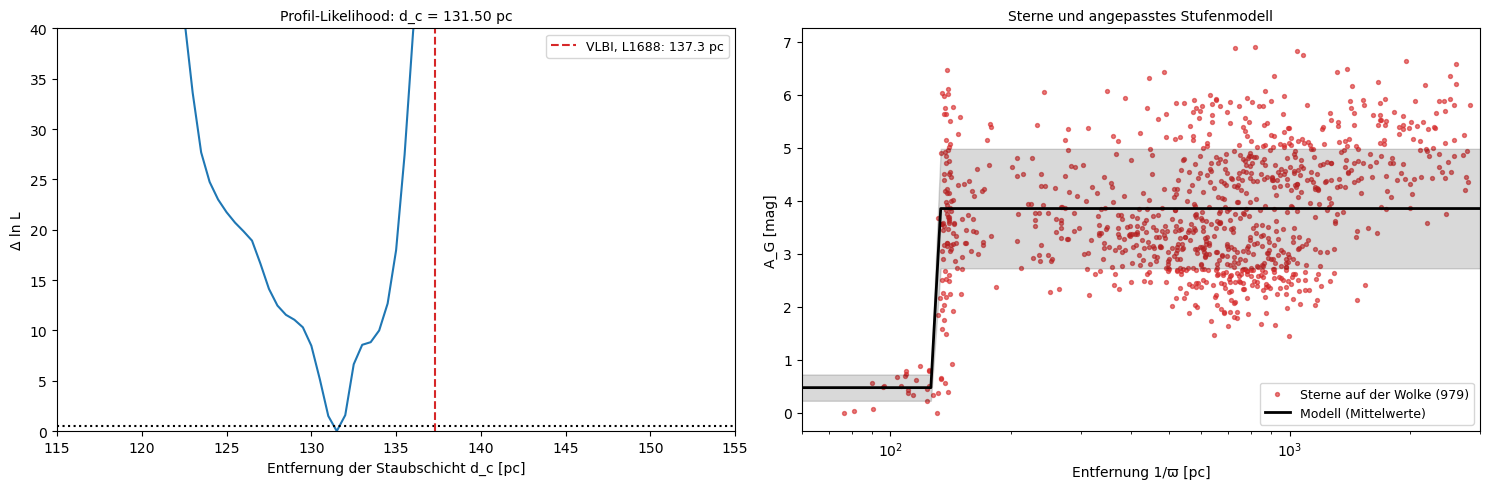

979 Sterne: d_c = 131.50 pc (Profil 1σ: 131.50 bis 131.50, Bootstrap ± 0.95 pc)
davor A_G = 0.48 ± 0.25, dahinter 3.86 ± 1.13 mag, Fremdanteil 0.0%
Sterne vor der Schicht: 25; nächster geröteter Stern (A_G > 2): 131.4 pc


In [10]:
cloud = GAIA[on & (GAIA["d"] < 3000)]
JUMP = fit_jump(cloud["ag_gspphot"].values, cloud["plx"].values, cloud["parallax_error"].values)
boot = []
for b in range(30):
    s = cloud.sample(len(cloud), replace=True, random_state=b)
    boot.append(fit_jump(s["ag_gspphot"].values, s["plx"].values, s["parallax_error"].values,
                         d_grid=np.arange(JUMP["d"] - 15, JUMP["d"] + 15, 0.5))["d"])
boot = np.array(boot)
D_JUMP, D_JUMP_ERR = JUMP["d"], np.std(boot)
inside = JUMP["grid"][JUMP["prof"] < 0.5]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.plot(JUMP["grid"], JUMP["prof"], "C0-")
ax.axhline(0.5, color="k", ls=":")
ax.axvline(137.3, color="C3", ls="--", label="VLBI, L1688: 137.3 pc")
ax.set_ylim(0, 40)
ax.set_xlim(115, 155)
ax.set_xlabel("Entfernung der Staubschicht d_c [pc]")
ax.set_ylabel("Δ ln L")
ax.set_title(f"Profil-Likelihood: d_c = {D_JUMP:.2f} pc", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
ax.scatter(cloud["d"], cloud["ag_gspphot"], s=8, c="C3", alpha=0.6, label=f"Sterne auf der Wolke ({len(cloud)})")
dd = np.linspace(60, 3000, 400)
ax.plot(dd, np.where(dd < D_JUMP, JUMP["a0"], JUMP["a1"]), "k-", lw=2, label="Modell (Mittelwerte)")
ax.fill_between(dd, np.where(dd < D_JUMP, JUMP["a0"] - JUMP["s0"], JUMP["a1"] - JUMP["s1"]),
                np.where(dd < D_JUMP, JUMP["a0"] + JUMP["s0"], JUMP["a1"] + JUMP["s1"]), color="k", alpha=0.15)
ax.set_xscale("log")
ax.set_xlim(60, 3000)
ax.set_xlabel("Entfernung 1/ϖ [pc]")
ax.set_ylabel("A_G [mag]")
ax.set_title("Sterne und angepasstes Stufenmodell", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"{JUMP['n']} Sterne: d_c = {D_JUMP:.2f} pc (Profil 1σ: {inside.min():.2f} bis {inside.max():.2f}, Bootstrap ± {D_JUMP_ERR:.2f} pc)")
print(f"davor A_G = {JUMP['a0']:.2f} ± {JUMP['s0']:.2f}, dahinter {JUMP['a1']:.2f} ± {JUMP['s1']:.2f} mag, Fremdanteil {JUMP['frac']:.1%}")
n_front = int(np.sum(cloud["d"] < D_JUMP))
print(f"Sterne vor der Schicht: {n_front}; nächster geröteter Stern (A_G > 2): {cloud.loc[cloud['ag_gspphot'] > 2, 'd'].min():.1f} pc")

* Links die Profil-Likelihood: Sie hat ein scharfes Minimum bei d_c = 131.5 pc, schon 1 pc daneben ist Δ ln L > 0.5; der Bootstrap über die Sterne gibt ± 1.0 pc. So genau wird es, weil die Parallaxen bei 7.6 mas auf etwa 1 % genau sind und der nächste stark gerötete Stern bei 131.4 pc steht.
* Rechts die 979 Sterne auf der Wolke mit dem Stufenmodell: davor A_G = 0.48 ± 0.25 (25 Sterne), dahinter 3.86 ± 1.13 mag. Der Fremdanteil wird null; die zwei Normalverteilungen beschreiben alle Sterne.
* Zur Vorhersage: Die Stufe liegt 6 pc vor den 137.3 pc, die VLBI für die jungen Sterne misst. Das Modell sucht die Vorderkante des Staubs; die jungen Sterne sitzen in der Wolke dahinter (Schritt 12).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-9"></a>

##### *9. Das Extinktionsgesetz im Infraroten*

Folgen die Farben der Sterne hinter der Wolke dem Rötungsvektor, den man aus Laboren und anderen Wolken kennt? Vorher vorhersagen: Ist das Verhältnis E(J−H)/E(H−K) in einer dichten Wolke größer oder kleiner als 1.70?

Für alle Sterne mit J, H und K und einer Extinktion zwischen A_V = 3 und 25 (gut gerötet, aber noch mit J gemessen) fittet der Code eine Gerade durch J−H gegen H−K. Weil beide Achsen Fehler haben, und zwar ungleich große (die Eigenfarben streuen in J−H doppelt so stark wie in H−K), nimmt er eine Deming-Regression mit dem Verhältnis der Fehlervarianzen und als Fehler einen Bootstrap. Junge Sterne mit Infrarotexzess liegen rechts unterhalb der Geraden; ein robuster Schnitt (3σ vom ersten Fit) entfernt sie.

**Hintergrund & Fachbegriffe:**
- **Extinktionsgesetz:** wie A_λ von der Wellenlänge abhängt. Im nahen Infrarot ist es in fast allen Richtungen ähnlich, etwa A_λ ∝ λ^(−1.7) bis λ^(−2).
- **Deming-Regression:** eine Gerade durch Punkte mit Fehlern in x und y, gewichtet mit dem Verhältnis δ der Fehlervarianzen; für δ = 1 ist es die orthogonale Regression (Hauptachse). Mit der falschen Gewichtung kippt die Gerade zur Achse mit dem größeren Fehler.

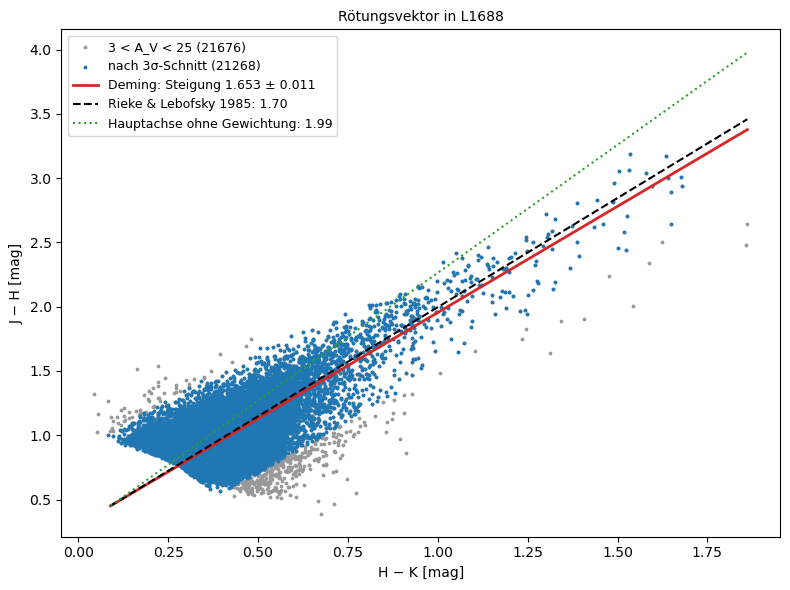

Varianzverhältnis der Fehler δ = 3.12; erster Fit 1.604, nach Schnitt (21268 von 21676) 1.653 ± 0.011; Hauptachse ohne Gewichtung 1.992; Rieke & Lebofsky 1.698
Entfernt (vor allem Infrarotexzess): 408 Sterne, davon unter der Geraden 349


In [11]:
red = STARS2M[STARS2M["has_j"] & STARS2M["AV"].between(3, 25)]


def principal_slope(x, y):
    c = np.cov(x, y)
    w, v = np.linalg.eigh(c)
    return v[1, 1] / v[0, 1]


def deming_slope(x, y, delta):
    # Gerade mit Fehlern in x und y, delta = Varianz(y-Fehler) / Varianz(x-Fehler)
    sxx, syy, sxy = np.var(x), np.var(y), np.cov(x, y, bias=True)[0, 1]
    return (syy - delta * sxx + np.sqrt((syy - delta * sxx) ** 2 + 4 * delta * sxy**2)) / (2 * sxy)


DELTA = (SIG_JH**2 + np.median(red["j_msigcom"] ** 2 + red["h_msigcom"] ** 2)) / \
        (SIG_HK**2 + np.median(red["h_msigcom"] ** 2 + red["k_msigcom"] ** 2))
s1 = deming_slope(red["hk"], red["jh"], DELTA)
resid = (red["jh"] - JH0) - s1 * (red["hk"] - HK0)
keep = np.abs(resid - resid.median()) < 3 * 1.4826 * np.median(np.abs(resid - resid.median()))
sel = red[keep]
SLOPE = deming_slope(sel["hk"], sel["jh"], DELTA)
SLOPE_PA = principal_slope(sel["hk"], sel["jh"])                    # Hauptachse ohne Fehlergewichtung, zum Vergleich
boot = [deming_slope(*sel.sample(len(sel), replace=True, random_state=b)[["hk", "jh"]].values.T, DELTA) for b in range(200)]
SLOPE_ERR = np.std(boot)
slope_rl = (R_JHK["J"] - R_JHK["H"]) / (R_JHK["H"] - R_JHK["K"])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(red["hk"], red["jh"], s=3, c="0.6", label=f"3 < A_V < 25 ({len(red)})")
ax.scatter(sel["hk"], sel["jh"], s=3, c="C0", label=f"nach 3σ-Schnitt ({len(sel)})")
x = np.linspace(HK0, red["hk"].max(), 50)
ax.plot(x, JH0 + SLOPE * (x - HK0), "C3-", lw=2, label=f"Deming: Steigung {SLOPE:.3f} ± {SLOPE_ERR:.3f}")
ax.plot(x, JH0 + slope_rl * (x - HK0), "k--", label=f"Rieke & Lebofsky 1985: {slope_rl:.2f}")
ax.plot(x, JH0 + SLOPE_PA * (x - HK0), "C2:", label=f"Hauptachse ohne Gewichtung: {SLOPE_PA:.2f}")
ax.set_xlabel("H − K [mag]")
ax.set_ylabel("J − H [mag]")
ax.set_title("Rötungsvektor in L1688", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"Varianzverhältnis der Fehler δ = {DELTA:.2f}; erster Fit {s1:.3f}, nach Schnitt ({len(sel)} von {len(red)}) "
      f"{SLOPE:.3f} ± {SLOPE_ERR:.3f}; Hauptachse ohne Gewichtung {SLOPE_PA:.3f}; Rieke & Lebofsky {slope_rl:.3f}")
print(f"Entfernt (vor allem Infrarotexzess): {len(red) - len(sel)} Sterne, davon unter der Geraden {np.sum(~keep & (resid < 0))}")

* Die blauen Punkte sind 21 268 gerötete Sterne mit 3 < A_V < 25 nach dem 3σ-Schnitt; 408 entfernte Sterne (grau) liegen fast alle (349) unter der Geraden, rechts im Diagramm: junge Sterne mit Infrarotexzess.
* Die Deming-Regression mit dem Fehlerverhältnis δ = 3.12 gibt E(J−H)/E(H−K) = 1.653 ± 0.011, knapp unter 1.70 von Rieke & Lebofsky (1985). Die ungewichtete Hauptachse (grün punktiert) gibt 1.99: Sie behandelt die größere Streuung in J−H als Steigung und kippt nach oben.
* Zur Vorhersage: kleiner als 1.70, aber nur um 3 %. Vermutlich ist ein Teil davon das andere Filtersystem (2MASS K_s statt Johnson K); große Unterschiede in der Korngröße zeigt L1688 im nahen Infrarot also nicht.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-10"></a>

##### *10. Staub, der verdeckt, gegen Staub, der leuchtet*

Wie viel Extinktion gehört zu einer Einheit optischer Tiefe bei 353 GHz, und ist das in der Wolke dasselbe wie im diffusen Gas der Milchstraße? Vorher vorhersagen: Wenn Staubkörner in kalten, dichten Wolken wachsen und mehr Submillimeterstrahlung pro Masse abgeben, ist A_V/τ353 dort größer oder kleiner als 4.6·10⁴?

Der Code vergleicht Pixel für Pixel die Extinktion aus 2MASS (Schritt 4) mit τ353 aus dem Fit (Schritt 6), nur in Pixeln mit mindestens fünf Sternen. Links A_V gegen τ353 mit dem Wert, den Planck an Quasaren hoher galaktischer Breite gemessen hat, rechts das Verhältnis gegen die Staubtemperatur. Mit dem gemessenen Verhältnis wird τ353 dann zu einer Extinktionskarte ohne Lücken, auch dort, wo 2MASS keine Sterne mehr sieht.

**Hintergrund & Fachbegriffe:**
- **Emissivität:** wie viel Strahlung eine Säule Staub pro Masse abgibt. Aus E(B−V)/τ353 = 1.49·10⁴ (Planck 2013 XI) folgt im diffusen Gas A_V/τ353 = 4.6·10⁴.
- **Kornwachstum:** In dichten, kalten Wolken frieren Moleküle auf den Körnern aus, und Körner verklumpen; beides erhöht die Emissivität im fernen Infrarot.

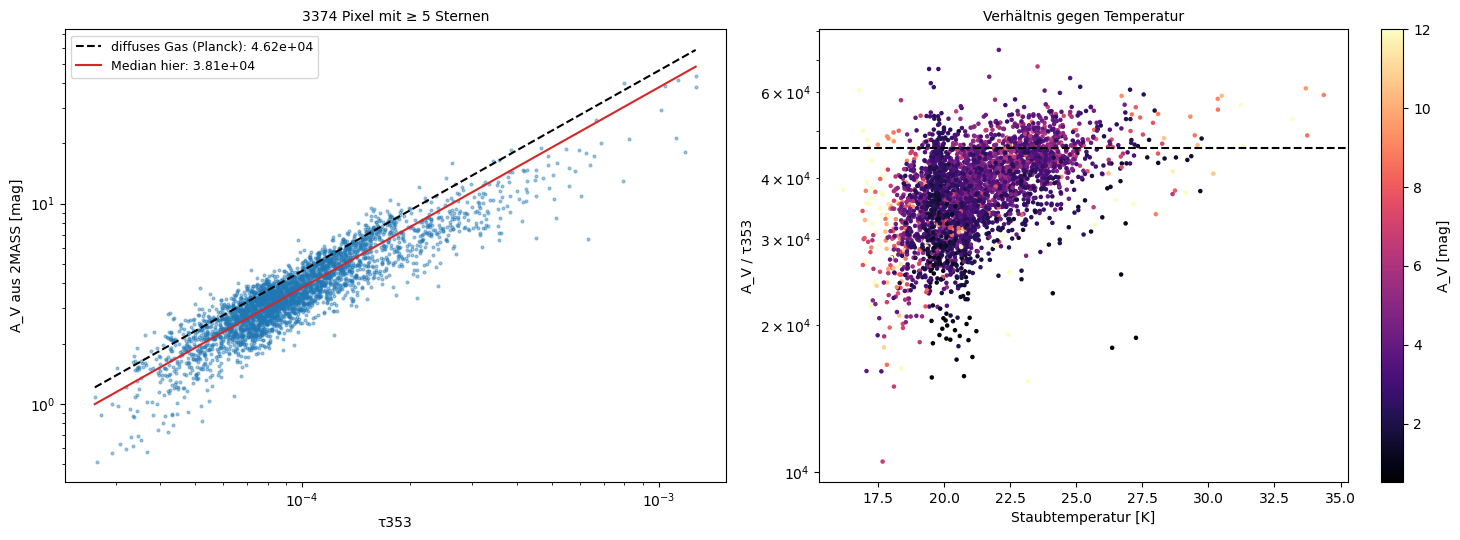

A_V/τ353: Median 3.81e+04 (16 % bis 84 %: 3.04e+04 bis 4.56e+04), diffus 4.62e+04: -18%
A_V  0.5 bis  3: 1211 Pixel, A_V/τ353 3.5e+04, T 20.5 K
A_V  3.0 bis  6: 1695 Pixel, A_V/τ353 4.02e+04, T 21.2 K
A_V  6.0 bis 10:  379 Pixel, A_V/τ353 4.03e+04, T 21.1 K
A_V 10.0 bis 40:   86 Pixel, A_V/τ353 3.37e+04, T 18.4 K
Rangkorrelation Verhältnis–Temperatur +0.53; A_V aus τ353: Maximum 50 mag (2MASS: 44)


In [12]:
use = (N_MAP >= 5) & np.isfinite(AV_MAP) & (AV_MAP > 0.5)
ratio = AV_MAP[use] / TAU[use]
AV_PER_TAU = np.median(ratio)
AV_TAU_MAP = AV_PER_TAU * TAU                                       # Extinktion aus τ353, ohne Lücken
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.scatter(TAU[use], AV_MAP[use], s=4, alpha=0.4)
t = np.logspace(np.log10(TAU[use].min()), np.log10(TAU[use].max()), 50)
ax.plot(t, AV_TAU_DIFFUSE * t, "k--", label=f"diffuses Gas (Planck): {AV_TAU_DIFFUSE:.2e}")
ax.plot(t, AV_PER_TAU * t, "C3-", label=f"Median hier: {AV_PER_TAU:.2e}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("τ353")
ax.set_ylabel("A_V aus 2MASS [mag]")
ax.set_title(f"{use.sum()} Pixel mit ≥ 5 Sternen", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
sc = ax.scatter(TEMP[use], ratio, c=AV_MAP[use], s=5, cmap="magma", vmax=12)
plt.colorbar(sc, ax=ax, label="A_V [mag]")
ax.axhline(AV_TAU_DIFFUSE, color="k", ls="--")
ax.set_yscale("log")
ax.set_xlabel("Staubtemperatur [K]")
ax.set_ylabel("A_V / τ353")
ax.set_title("Verhältnis gegen Temperatur", fontsize=10)
plt.tight_layout()
plt.show()

print(f"A_V/τ353: Median {AV_PER_TAU:.3g} (16 % bis 84 %: {np.percentile(ratio, 16):.3g} bis {np.percentile(ratio, 84):.3g}), "
      f"diffus {AV_TAU_DIFFUSE:.3g}: {AV_PER_TAU / AV_TAU_DIFFUSE - 1:+.0%}")
for lo, hi in [(0.5, 3), (3, 6), (6, 10), (10, 40)]:
    m = use & (AV_MAP >= lo) & (AV_MAP < hi)
    if m.any():
        print(f"A_V {lo:4.1f} bis {hi:2d}: {m.sum():4d} Pixel, A_V/τ353 {np.median(AV_MAP[m] / TAU[m]):.3g}, T {np.median(TEMP[m]):.1f} K")
print(f"Rangkorrelation Verhältnis–Temperatur {stats.spearmanr(TEMP[use], ratio).statistic:+.2f}; "
      f"A_V aus τ353: Maximum {AV_TAU_MAP.max():.0f} mag (2MASS: {np.nanmax(AV_MAP):.0f})")

* Links A_V aus 2MASS gegen τ353 aus Planck für 3374 Pixel: Die Punkte liegen auf einer Geraden, aber unter der Linie des diffusen Gases. Im Median ist A_V/τ353 = 3.81·10⁴ (16 % bis 84 %: 3.04 bis 4.56·10⁴), 18 % weniger als 4.62·10⁴.
* Rechts das Verhältnis gegen die Temperatur: Rangkorrelation +0.53. In den dichtesten Pixeln (A_V > 10, 18.4 K) ist es 3.37·10⁴, bei mittlerer Säule (A_V 3 bis 10, 21 K) 4.0·10⁴. Wie vorhergesagt strahlt kalter Staub in dichten Wolken pro Extinktion mehr, ein Hinweis auf gewachsene oder vereiste Körner. Dass auch die dünnsten Pixel (A_V < 3) ein kleines Verhältnis haben (3.5·10⁴), liegt vermutlich am Staub hinter den Sternen, den Planck mitsieht, 2MASS aber nicht.
* Mit diesem Verhältnis wird τ353 zu einer Extinktionskarte ohne Lücken: Sie erreicht im Kern 50 mag, mehr als die 44 mag, die 2MASS mit den letzten sichtbaren Sternen misst.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-11"></a>

##### *11. Die Masse der Wolke*

Wie viel Gas steckt in L1688 und seiner Umgebung, und wie viel davon ist dicht genug, um Sterne zu bilden? Vorher vorhersagen: Liegt die Masse über A_V = 7 eher bei einem Prozent, zehn Prozent oder der Hälfte der Masse über A_V = 1?

Aus der Extinktion folgt die Säule Wasserstoff, N_H = 1.87·10²¹ cm⁻² pro Magnitude A_V, und mit Helium die Masse pro Fläche, Σ = 1.37 m_H N_H (Theorie, Abschnitt 3). Mit der Entfernung aus Schritt 8 wird die Fläche eines Pixels physikalisch. Summiert wird über alle Pixel oberhalb einer Schwelle, einmal mit der Karte aus 2MASS (Lücken mit der τ-Karte gefüllt), einmal nur mit τ353. Links die Masse über der Schwelle, rechts die Fläche.

**Hintergrund & Fachbegriffe:**
- **Säulendichte:** Zahl der Atome in einer Säule von 1 cm² Querschnitt entlang der Sichtlinie.
- **Schwelle A_V ≈ 7:** Unterhalb davon bilden sich kaum Sterne; fast alle jungen Sterne liegen in Gas mit mehr Extinktion (Lada et al. 2010). Der Anteil der Masse über dieser Schwelle bestimmt, wie viele Sterne eine Wolke bildet.

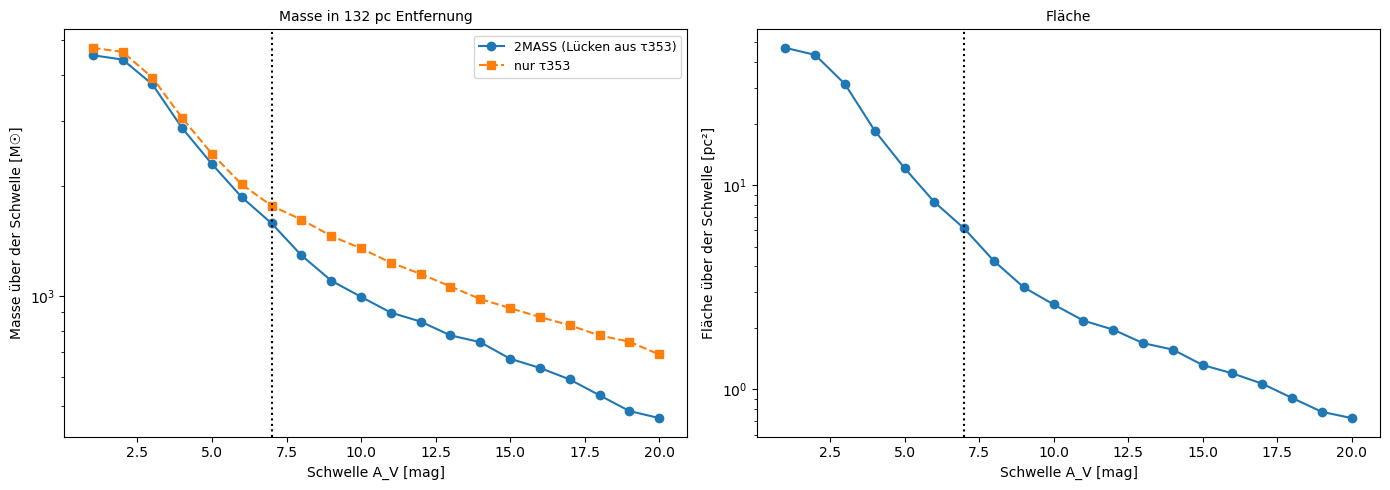

Ein Pixel: 0.115 pc Kantenlänge, 0.270 M☉ pro Magnitude A_V
A_V >  1: 2MASS    4537 M☉ auf  47.0 pc², nur τ    4754 M☉
A_V >  3: 2MASS    3779 M☉ auf  31.2 pc², nur τ    3940 M☉
A_V >  7: 2MASS    1576 M☉ auf   6.1 pc², nur τ    1761 M☉
A_V > 15: 2MASS     673 M☉ auf   1.3 pc², nur τ     925 M☉
Anteil der Masse über A_V = 7 an der über A_V = 1: 35%; ganzes Feld 4543 M☉


In [13]:
D_CLOUD = D_JUMP                                                    # Entfernung aus Schritt 8 [pc]
pix_cm = np.radians(SIZE / NPIX_MAP) * D_CLOUD * PC
mass_per_mag = MU_H * M_H * NH_PER_AV * pix_cm**2 / M_SUN           # Sonnenmassen pro Pixel und Magnitude A_V
AV_BEST = np.where(np.isfinite(AV_MAP), AV_MAP, AV_TAU_MAP)
thresholds = np.arange(1, 21)
M_2M = np.array([np.sum(AV_BEST[AV_BEST > t]) * mass_per_mag for t in thresholds])
M_TAU = np.array([np.sum(AV_TAU_MAP[AV_TAU_MAP > t]) * mass_per_mag for t in thresholds])
A_2M = np.array([np.sum(AV_BEST > t) for t in thresholds]) * (pix_cm / PC) ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.semilogy(thresholds, M_2M, "o-", label="2MASS (Lücken aus τ353)")
ax.semilogy(thresholds, M_TAU, "s--", label="nur τ353")
ax.axvline(7, color="k", ls=":")
ax.set_xlabel("Schwelle A_V [mag]")
ax.set_ylabel("Masse über der Schwelle [M☉]")
ax.set_title(f"Masse in {D_CLOUD:.0f} pc Entfernung", fontsize=10)
ax.legend(fontsize=9)
ax = axes[1]
ax.semilogy(thresholds, A_2M, "o-")
ax.axvline(7, color="k", ls=":")
ax.set_xlabel("Schwelle A_V [mag]")
ax.set_ylabel("Fläche über der Schwelle [pc²]")
ax.set_title("Fläche", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Ein Pixel: {pix_cm / PC:.3f} pc Kantenlänge, {mass_per_mag:.3f} M☉ pro Magnitude A_V")
for t in (1, 3, 7, 15):
    k = t - 1
    print(f"A_V > {t:2d}: 2MASS {M_2M[k]:7.0f} M☉ auf {A_2M[k]:5.1f} pc², nur τ {M_TAU[k]:7.0f} M☉")
print(f"Anteil der Masse über A_V = 7 an der über A_V = 1: {M_2M[6] / M_2M[0]:.0%}; ganzes Feld {np.sum(AV_BEST) * mass_per_mag:.0f} M☉")

* Links die Masse über einer Schwelle der Extinktion, rechts die Fläche. In 131.5 pc ist ein Pixel 0.115 pc groß und trägt 0.27 M☉ pro Magnitude A_V. Über A_V = 1 liegen 4537 M☉ auf 47 pc², über A_V = 7 noch 1576 M☉ auf 6.1 pc², über A_V = 15 673 M☉ auf 1.3 pc².
* Zur Vorhersage: Über A_V = 7 liegt gut ein Drittel (35 %) der Masse über A_V = 1. Diese dichte Masse sitzt im Kern von L1688 und in den Filamenten nach Osten, dort, wo die jungen Sterne liegen.
* Die Karte nur aus τ353 gibt bei kleinen Schwellen dasselbe (4754 M☉ über A_V = 1) und bei großen mehr (925 statt 673 M☉ über A_V = 15): In den Kernen, wo 2MASS keine Sterne mehr sieht und der Median zu klein wird, findet Planck mehr Staub. Mit der VLBI-Entfernung (137 pc) wären alle Massen 9 % größer.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung gegen den Katalog**

<a id="exp-12"></a>

##### *12. Die Entfernung gegen VLBI und Hipparcos*

Wie passt die Entfernung aus dem Sprung zu den Parallaxen junger Sterne in der Wolke und zu älteren Messungen? Vorher vorhersagen: Liegt die Messung mit Hipparcos von 2008 näher oder ferner als Gaia?

Ortiz-León et al. (2017) haben mit dem Very Long Baseline Array die Parallaxen von zwölf jungen Sternsystemen in L1688 und drei in L1689 gemessen, Radiosterne mit Positionen auf 0.1 Millibogensekunden. Lombardi, Lada & Alves (2008) haben mit derselben Idee wie hier (Sprung der Extinktion, Maximum Likelihood) aus Hipparcos- und Tycho-Parallaxen 119 ± 6 pc bestimmt. Der Code vergleicht und prüft die eigene Messung auf Systematik: anderer Schnitt auf der Wolke, Parallaxen ohne Nullpunkt, nur die West- und nur die Osthälfte des Feldes (L1688 liegt nahe der Mitte, L1689 im Osten).

**Hintergrund & Fachbegriffe:**
- **VLBI:** Very Long Baseline Interferometry, Radioteleskope über einen Kontinent zusammengeschaltet; die Auflösung entspricht einem Teleskop von der Größe des Kontinents. Junge Sterne mit starken Magnetfeldern senden Radiostrahlung aus und lassen sich so astrometrisch verfolgen.
- **Hipparcos:** der Astrometriesatellit der ESA (1989 bis 1993), Vorgänger von Gaia; Parallaxen auf etwa 1 mas genau, für 118 000 helle Sterne.
- **Vorderkante und Mitte:** Der Sprung markiert, wo der Staub beginnt; junge Sterne sitzen in der Wolke. Ist die Wolke einige Parsec tief, liegen sie hinter der Vorderkante.

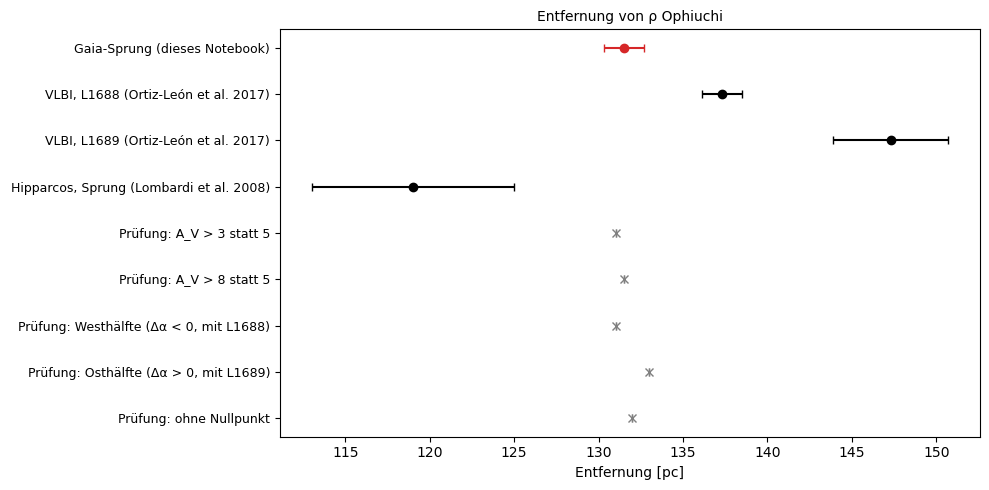

Gaia-Sprung: 131.5 ± 1.0 (Bootstrap) ± 0.7 (Schnitte, Nullpunkt) pc
  A_V > 3 statt 5         :  131.0 pc
  A_V > 8 statt 5         :  131.5 pc
  Westhälfte (Δα < 0, mit L1688):  131.0 pc
  Osthälfte (Δα > 0, mit L1689):  133.0 pc
  ohne Nullpunkt          :  132.0 pc
VLBI, L1688 (Ortiz-León et al. 2017)      :  137.3 ± 1.2 pc, Unterschied -5.8 pc
VLBI, L1689 (Ortiz-León et al. 2017)      :  147.3 ± 3.4 pc, Unterschied -15.8 pc
Hipparcos, Sprung (Lombardi et al. 2008)  :  119.0 ± 6.0 pc, Unterschied +12.5 pc


In [14]:
LIT = {"VLBI, L1688 (Ortiz-León et al. 2017)": (137.3, 1.2), "VLBI, L1689 (Ortiz-León et al. 2017)": (147.3, 3.4),
       "Hipparcos, Sprung (Lombardi et al. 2008)": (119.0, 6.0)}
CHECKS = {}
for lab, m in [("A_V > 3 statt 5", GAIA["in_field"] & ((GAIA["AV_map"] > 3) | GAIA["empty"])),
               ("A_V > 8 statt 5", GAIA["in_field"] & ((GAIA["AV_map"] > 8) | GAIA["empty"])),
               ("Westhälfte (Δα < 0, mit L1688)", on & (offsets(GAIA["ra"], GAIA["dec"])[0] < 0)),
               ("Osthälfte (Δα > 0, mit L1689)", on & (offsets(GAIA["ra"], GAIA["dec"])[0] > 0))]:
    s = GAIA[m & (GAIA["d"] < 3000)]
    CHECKS[lab] = fit_jump(s["ag_gspphot"].values, s["plx"].values, s["parallax_error"].values,
                           d_grid=np.arange(100, 180, 0.5))["d"]
s = cloud
CHECKS["ohne Nullpunkt"] = fit_jump(s["ag_gspphot"].values, s["parallax"].values, s["parallax_error"].values,
                                    d_grid=np.arange(100, 180, 0.5))["d"]
D_SYS = np.std([v for k, v in CHECKS.items() if "Osten" not in k and "Westen" not in k] + [D_JUMP])

fig, ax = plt.subplots(figsize=(10, 5))
items = [("Gaia-Sprung (dieses Notebook)", (D_JUMP, np.hypot(D_JUMP_ERR, D_SYS)))] + list(LIT.items()) + \
        [(f"  Prüfung: {k}", (v, 0)) for k, v in CHECKS.items()]
for i, (lab, (d, e)) in enumerate(items):
    ax.errorbar(d, -i, xerr=e, fmt="o" if "Prüfung" not in lab else "x", color="C3" if i == 0 else ("k" if "Prüfung" not in lab else "0.5"),
                capsize=3)
ax.set_yticks([-i for i in range(len(items))])
ax.set_yticklabels([lab for lab, _ in items], fontsize=9)
ax.set_xlabel("Entfernung [pc]")
ax.set_title("Entfernung von ρ Ophiuchi", fontsize=10)
plt.tight_layout()
plt.show()

print(f"Gaia-Sprung: {D_JUMP:.1f} ± {D_JUMP_ERR:.1f} (Bootstrap) ± {D_SYS:.1f} (Schnitte, Nullpunkt) pc")
for k, v in CHECKS.items():
    print(f"  {k:24s}: {v:6.1f} pc")
for k, (d, e) in LIT.items():
    print(f"{k:42s}: {d:6.1f} ± {e:.1f} pc, Unterschied {D_JUMP - d:+.1f} pc")

* Oben die eigene Entfernung, 131.5 ± 1.0 (statistisch) ± 0.7 pc (Schnitte und Nullpunkt), darunter die Literatur und grau die Prüfungen: andere Schwellen 131.0 und 131.5 pc, Parallaxen ohne Nullpunkt 132.0 pc, West- und Osthälfte 131.0 und 133.0 pc.
* VLBI misst für die jungen Sterne in L1688 137.3 ± 1.2 pc, 5.8 pc mehr, und für L1689 147.3 ± 3.4 pc. Die Osthälfte gibt nur 133 pc; vermutlich setzt dort der Staub der Ausläufer schon vor L1689 ein. Meine Deutung des Unterschieds: Die Stufe misst die Vorderkante des Staubs, die jungen Sterne sitzen in der Wolke, und die Wolke ist entlang der Sichtlinie einige Parsec tief.
* Zur Vorhersage: Hipparcos mit derselben Methode (Lombardi et al. 2008) gab 119 ± 6 pc, 12.5 pc weniger als Gaia. Damals standen nur wenige helle Sterne mit Parallaxen auf etwa 1 mas zur Verfügung; jetzt sind es tausend mit Fehlern von einigen hundertstel mas.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-13"></a>

##### *13. Die Extinktion gegen die Staubkarte von Schlegel, Finkbeiner & Davis*

Wie gut beschreibt die meistbenutzte Staubkarte der Astronomie die Extinktion in einer Molekülwolke? Vorher vorhersagen: Wo wird eine Karte, die die Temperatur des Staubs nur auf 1° Auflösung kennt, die Extinktion am stärksten überschätzen?

Schlegel, Finkbeiner & Davis (1998) haben aus der 100-µm-Strahlung (IRAS) und einer groben Temperaturkarte (DIRBE, etwa 1°) E(B−V) für den ganzen Himmel berechnet; sie wird für fast jedes extragalaktische Objekt zur Korrektur benutzt. Der Code holt die Karte für das Feld vom Staubdienst bei IRSA, rechnet sie mit R_V = 3.1 in A_V um und vergleicht Pixel für Pixel mit der Karte aus 2MASS, in Abhängigkeit von der Staubtemperatur aus Schritt 6.

**Hintergrund & Fachbegriffe:**
- **SFD-Karte:** nach den Autoren benannt; E(B−V) = Emission bei 100 µm, korrigiert auf eine Bezugstemperatur und mit Galaxienfarben geeicht. Schlafly & Finkbeiner (2011) haben sie mit Sternspektren um den Faktor 0.86 nachgeeicht.
- **Temperaturkorrektur:** Warmer Staub strahlt bei 100 µm viel mehr pro Masse als kalter; kennt die Karte die Temperatur falsch, schätzt sie die Menge falsch, bei 100 µm etwa mit T^(4+β) über dem Spektrum.

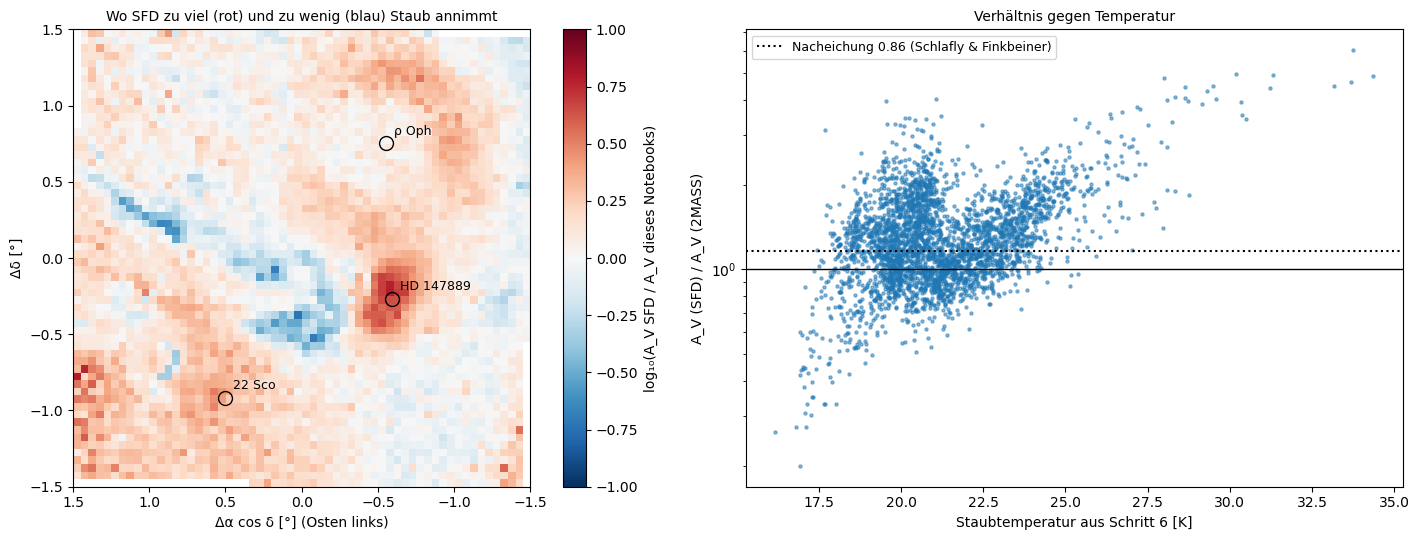

3309 Pixel: SFD/2MASS Median 1.24 (16 % bis 84 %: 0.91 bis 1.79); Rangkorrelation mit T +0.28
T 15 bis 19 K:  348 Pixel, SFD/2MASS 1.08
T 19 bis 21 K: 1436 Pixel, SFD/2MASS 1.25
T 21 bis 23 K:  882 Pixel, SFD/2MASS 1.11
T 23 bis 40 K:  643 Pixel, SFD/2MASS 1.58
Pixel ohne SFD-Wert (Rand des Ausschnitts): 67
Größtes A_V in SFD: 62 mag bei T = 31.3 K, 4.7′ von HD 147889; 2MASS/τ dort 12.5 mag


In [15]:
wsfd = WCS(SFD.header)
px, py = wsfd.world_to_pixel_values(RA_MAP, DE_MAP)
SFD_AV = 3.1 * map_coordinates(SFD.data.astype(float), [py, px], order=1, cval=np.nan)
use = (N_MAP >= 5) & np.isfinite(AV_MAP) & (AV_MAP > 0.5) & np.isfinite(SFD_AV)
q = SFD_AV[use] / AV_MAP[use]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
im = ax.imshow(np.log10(SFD_AV / AV_BEST), origin="lower", cmap="RdBu_r", vmin=-1, vmax=1, extent=EXT_MAP)
plt.colorbar(im, ax=ax, label="log₁₀(A_V SFD / A_V dieses Notebooks)")
for name, (ra, dec) in STARS.items():
    x, y = offsets(ra, dec)
    ax.plot(x, y, "o", mfc="none", mec="k", ms=10)
    ax.annotate(name, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=9)
ax.set_title("Wo SFD zu viel (rot) und zu wenig (blau) Staub annimmt", fontsize=10)
ax.set_xlabel("Δα cos δ [°] (Osten links)")
ax.set_ylabel("Δδ [°]")
ax = axes[1]
ax.scatter(TEMP[use], q, s=5, alpha=0.5)
ax.axhline(1, color="k", lw=1)
ax.axhline(1 / 0.86, color="k", ls=":", label="Nacheichung 0.86 (Schlafly & Finkbeiner)")
ax.set_yscale("log")
ax.set_xlabel("Staubtemperatur aus Schritt 6 [K]")
ax.set_ylabel("A_V (SFD) / A_V (2MASS)")
ax.set_title("Verhältnis gegen Temperatur", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"{use.sum()} Pixel: SFD/2MASS Median {np.median(q):.2f} (16 % bis 84 %: {np.percentile(q, 16):.2f} bis {np.percentile(q, 84):.2f}); "
      f"Rangkorrelation mit T {stats.spearmanr(TEMP[use], q).statistic:+.2f}")
for lo, hi in [(15, 19), (19, 21), (21, 23), (23, 40)]:
    m = (TEMP[use] >= lo) & (TEMP[use] < hi)
    if m.any():
        print(f"T {lo} bis {hi} K: {m.sum():4d} Pixel, SFD/2MASS {np.median(q[m]):.2f}")
print(f"Pixel ohne SFD-Wert (Rand des Ausschnitts): {np.sum(~np.isfinite(SFD_AV))}")
i, j = np.unravel_index(np.nanargmax(SFD_AV), SFD_AV.shape)
print(f"Größtes A_V in SFD: {SFD_AV[i, j]:.0f} mag bei T = {TEMP[i, j]:.1f} K, {R_ARC[i, j]:.1f}′ von HD 147889; "
      f"2MASS/τ dort {AV_BEST[i, j]:.1f} mag")

* Links das Verhältnis der SFD-Karte zur eigenen Extinktion (Lücken mit τ353 gefüllt): rot, wo SFD mehr Staub annimmt, blau, wo weniger. Rot sind die Umgebung von HD 147889, ein Bogen um ρ Oph und die warme Südwestecke, blau die kalten Filamente im Osten und Süden: genau das Muster der Temperaturkarte aus Schritt 6.
* Rechts das Verhältnis gegen die Staubtemperatur für 3309 Pixel: Median 1.24 (0.91 bis 1.79), bei 15 bis 19 K 1.08, über 23 K 1.58. Wie vorhergesagt überschätzt SFD die Extinktion dort, wo der Staub wärmer ist, als seine grobe Temperaturkarte annimmt, und unterschätzt sie in kaltem Staub.
* Der extremste Fall ist der Pixel 4.7′ neben HD 147889: SFD gibt A_V = 62 mag, 2MASS und τ353 geben 12.5 mag. Wer dort die Rötung eines Hintergrundobjekts aus SFD korrigiert, macht es um 50 mag zu hell. Auch im Mittel liegt SFD um 24 % über 2MASS, etwas mehr als die Nacheichung von Schlafly & Finkbeiner erwarten lässt (1/0.86 = 1.16).

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-08 (2MASS, Gaia DR3, IRIS, Planck PR3, Feld 3° × 3° um L1688, Rechengitter 3′):

- **Sterne und Farben:** Von 102 443 2MASS-Quellen im Feld bleiben 37 640 mit guter Photometrie in H und K. Das Kontrollfeld 5.5° südwestlich (E(B−V) = 0.14) gibt die Eigenfarben (H−K)₀ = 0.090 ± 0.073 und (J−H)₀ = 0.450 ± 0.156; jeder Stern misst A_V damit auf 1.1 mag.
- **Extinktionskarte:** 3542 von 3600 Pixeln haben mindestens drei Sterne; A_V im Median 3.5 mag, 95 % unter 9.2 mag, im Kern bis 44 mag. Die Rangkorrelation mit Planck 857 GHz ist 0.91.
- **Staubtemperatur:** Modifizierter Schwarzkörper an vier Bänder: T = 20.8 K im Median (18.3 bis 24.8 K), β = 1.56; die dichtesten Pixel haben 18.3 K, der wärmste 36.6 K neben HD 147889. Die Heizung durch HD 147889 fällt mit r^(−2.10 ± 0.13), der Stern heizt bis 12.3′ (0.49 pc) so stark wie die übrige Milchstraße.
- **Entfernung:** Die Gaia-Extinktion springt bei **131.5 ± 1.0 (statistisch) ± 0.7 pc (systematisch)** von 0.48 auf 3.86 mag (979 Sterne). VLBI misst für die jungen Sterne in L1688 137.3 ± 1.2 pc, Hipparcos gab mit derselben Methode 119 ± 6 pc.
- **Extinktionsgesetz und Emissivität:** E(J−H)/E(H−K) = 1.653 ± 0.011 (Rieke & Lebofsky: 1.70; ungewichtete Hauptachse 1.99). A_V/τ353 = 3.81·10⁴, 18 % unter dem Wert des diffusen Gases, in den kältesten, dichtesten Pixeln 3.37·10⁴.
- **Masse:** In 131.5 pc liegen 4537 M☉ über A_V = 1 (47 pc²) und 1576 M☉ über A_V = 7 (6.1 pc², 35 %); die Karte aus τ353 gibt 4754 und 1761 M☉.
- **Staubkarte SFD:** Im Median 1.24-mal die Extinktion aus 2MASS, über 23 K 1.58-mal; neben HD 147889 62 statt 12.5 mag.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und das Notebook neu ausführen:

1. **Ein Stern pro Pixel genügt:** `MIN_STARS = 1` statt 3. *(Vorhersage: Die Karte deckt 3590 statt 3542 Pixel ab, das Maximum steigt von 44 auf 61 mag, aber die Masse über A_V = 7 sinkt leicht (1523 statt 1576 M☉). In den dichtesten Pixeln kommen nur die am wenigsten geröteten Sterne durch, ein oder zwei solche Sterne unterschätzen A_V; vorher füllte dort die τ-Karte die Lücke.)*
2. **Nur H−K, wie die Methode NICE:** In `av_star` die Gewichte von J−H auf null setzen: `w_hk, w_jh = 1 / var_hk, np.zeros(len(t))`. *(Vorhersage: Der Fehler pro Stern steigt von 1.08 auf 1.51 mag, die Karte wird rauschiger (Median 3.36 statt 3.50). Die Steigung in Schritt 9 springt auf 2.23: Die Auswahl 3 < A_V < 25 hängt jetzt nur an H−K, also an der x-Achse, und eine Regression mit Fehlern in beiden Achsen wird durch eine Auswahl nach einer Achse verzerrt.)*
3. **Steilerer Spektralindex:** `BETA_FIX = 2.0` statt 1.6. *(Vorhersage: T und β vertreten sich: Mit β = 2 ist der Staub im Median 18.3 statt 20.7 K warm, der Hintergrund 18.4 statt 20.9 K. Das Heizgesetz bleibt: n = 2.04, r₀ = 11.5′. Absolute Temperaturen hängen am angenommenen β, das Abstandsgesetz nicht.)*
4. **Die Entfernung von VLBI:** `D_CLOUD = 137.3` statt der eigenen Entfernung. *(Vorhersage: Alle Massen wachsen mit d² um (137.3/131.5)² = 1.09: 4946 statt 4537 M☉ über A_V = 1, 1718 statt 1576 über A_V = 7.)*
5. **Die Rötung des Kontrollfelds vergessen:** `av_ctrl = 0.0` statt 3.1 · E(B−V). *(Vorhersage: Die Eigenfarben werden um die Rötung des Kontrollfelds zu rot angenommen, jedes A_V sinkt um 0.43 mag (Median 3.07 statt 3.50). Die Masse über A_V = 1 fällt um 10 % auf 4061 M☉, A_V/τ353 auf 3.31·10⁴, und SFD scheint 42 % statt 24 % zu hoch. Ein kleiner Nullpunktfehler wirkt auf alle abgeleiteten Größen.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum ist eine Dunkelwolke im Blauen dunkel und im fernen Infraroten hell?</summary>

Der Staub schluckt das Licht der Sterne dahinter, blaues stärker als rotes, und erwärmt sich dabei auf 15 bis 40 K. Diese Energie strahlt er als Wärmestrahlung bei 100 µm bis 1 mm wieder ab. Absorption und Emission sind zwei Seiten desselben Staubs.
</details>

<details><summary>2. Wie misst man mit den Farben von Sternen die Extinktion?</summary>

Im nahen Infrarot haben fast alle Sterne ähnliche Eigenfarben, (H−K)₀ ≈ 0.09. Staub macht sie röter, und zwar um E(H−K) = 0.063 mag pro Magnitude A_V. Aus der gemessenen Farbe folgt A_V = 15.9 · [(H−K) − (H−K)₀], pro Stern auf etwa 1 mag genau, im Median vieler Sterne viel genauer.
</details>

<details><summary>3. Wozu braucht man das Kontrollfeld?</summary>

Für die Eigenfarben: Dort liegt fast kein Staub, die Sterne zeigen ihre Farben ohne Rötung. Das Feld muss auf ähnlicher galaktischer Breite liegen, damit die Mischung der Sterntypen dieselbe ist; seine kleine Rötung (A_V = 0.43) wird abgezogen.
</details>

<details><summary>4. Warum taugt 2MASS für die Extinktionskarte besser als Gaia?</summary>

Im Band K ist die Extinktion neunmal kleiner als im Visuellen. Hinter A_V = 10 sind Sterne im Optischen 10⁴-fach schwächer, im Band K nur um 1.1 mag. Gaia sieht deshalb hinter dem Kern fast keine Sterne mehr (0.3 pro Pixel), 2MASS noch fünf.
</details>

<details><summary>5. Wie bestimmt man die Entfernung einer Wolke aus der Rötung der Sterne?</summary>

Sterne vor der Wolke sind kaum gerötet, Sterne dahinter stark. Mit Parallaxen kennt man ihre Entfernung, und die Entfernung, ab der die Rötung springt, ist die Entfernung der Wolke. Die Likelihood berücksichtigt den Parallaxenfehler jedes Sterns als Wahrscheinlichkeit, vor der Wolke zu stehen.
</details>

<details><summary>6. Warum liegt die Entfernung aus dem Sprung (131.5 pc) unter der von VLBI (137.3 pc)?</summary>

Der Sprung markiert die Vorderkante des Staubs; VLBI misst junge Sterne, die in der Wolke sitzen. Ist die Wolke einige Parsec tief, liegen die Sterne hinter der Vorderkante. Diese Deutung ist eine Vermutung; Parallaxen-Nullpunkt und Schnitte verschieben die Stufe nur um 0.7 pc.
</details>

<details><summary>7. Was ist ein modifizierter Schwarzkörper, und was bedeutet β?</summary>

I_ν = τ353 (ν/353 GHz)^β B_ν(T): ein Schwarzkörper, dessen Abstrahlung zu langen Wellen hin mit ν^β schwächer wird, weil die Körner viel kleiner sind als die Wellenlänge. β ≈ 1.5 bis 2 hängt vom Material und von der Struktur der Körner ab; hier 1.56.
</details>

<details><summary>8. Warum ist der Staub in den dichtesten Teilen der Wolke am kältesten?</summary>

Er wird vom Licht der Sterne geheizt, und in dichte Kerne dringt nur wenig davon ein; außen absorbiert der Staub das Licht schon. Die dichtesten Pixel haben 18.3 K, der Rest 20.9 K.
</details>

<details><summary>9. Welches Gesetz erwartet man für die Temperatur um einen heizenden Stern, und was wurde gemessen?</summary>

Die Heizleistung fällt mit 1/r², die Abstrahlung wächst mit T^(4+β); also T^(4+β) − T_b^(4+β) ∝ r^(−2). Gemessen ist r^(−2.10 ± 0.13) zwischen 5′ und 30′ um HD 147889.
</details>

<details><summary>10. Warum gab die ungewichtete Hauptachse ein falsches Extinktionsgesetz?</summary>

Die Eigenfarben streuen in J−H doppelt so stark wie in H−K. Eine Hauptachse ohne Gewichtung behandelt beide Richtungen gleich und kippt zur Achse mit der größeren Streuung; das gab 1.99 statt 1.65. Die Deming-Regression gewichtet mit dem Verhältnis der Fehlervarianzen.
</details>

<details><summary>11. Was sagt ein A_V/τ353 unter dem Wert des diffusen Gases?</summary>

Dass der Staub pro Extinktion mehr im Submillimeterbereich strahlt. In kalten, dichten Wolken wachsen die Körner und bekommen Eismäntel, und ihr Emissionsvermögen steigt. Hier sind es 18 % weniger als im diffusen Gas, im kalten Kern noch weniger.
</details>

<details><summary>12. Warum überschätzt die SFD-Karte die Extinktion neben HD 147889 so stark?</summary>

SFD rechnet die 100-µm-Strahlung mit einer Temperaturkarte von etwa 1° Auflösung in Staubmenge um. Der 30 K warme Staub neben dem Stern strahlt bei 100 µm viel mehr als 20 K warmer Staub derselben Menge; SFD hält das für mehr Staub und gibt 62 statt 12.5 mag.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Dreidimensionale Staubkarten:** Mit Millionen Gaia-Sternen und ihren Extinktionen rekonstruieren Forschende den Staub in der Umgebung der Sonne als 3D-Karte (Leike & Enßlin 2019, Edenhofer et al. 2024); die Wolke von ρ Ophiuchi erscheint darin als gekrümmte Schicht mit Tiefe, die die Frage der Vorderkante direkt beantwortet.
- **Höhere Auflösung:** Herschel hat ρ Ophiuchi bei 70 bis 500 µm mit 10″ bis 36″ kartiert; damit zerfällt die Wolke in Filamente und einzelne Kerne, deren Massen und Temperaturen man mit dem Virialsatz auf Kollaps prüft.
- **Gas statt Staub:** CO und seine Isotope (¹³CO, C¹⁸O) messen das Gas und seine Geschwindigkeiten; der Vergleich mit der Extinktion zeigt, wo CO auf den Körnern ausfriert.
- **Sternentstehung zählen:** Junge Sterne aus Spitzer- und WISE-Daten zählen und mit der Masse über A_V ≈ 7 vergleichen; das ist der Test, ob die Sternentstehungsrate an der dichten Masse hängt (Lada et al. 2010).
- **Das Staubgesetz im Ultravioletten und Optischen:** Mit Gaia-BP/RP-Spektren oder Spektren der Sterne hinter der Wolke misst man R_V; in dichten Wolken ist es oft größer als 3.1, ein weiteres Zeichen für gewachsene Körner.

#### **Referenzen**

- Draine, B. T. (2011): *Physics of the Interstellar and Intergalactic Medium*, Princeton (Kapitel zu Extinktion und Rötung, zur Temperatur von Staubkörnern und zu Molekülwolken).
- Rieke, G. H. & Lebofsky, M. J. (1985): *The interstellar extinction law from 1 to 13 microns*, ApJ 288, 618.
- Lada, C. J., Lada, E. A., Clemens, D. P. & Bally, J. (1994): *Dust extinction and molecular gas in the dark cloud IC 5146*, ApJ 429, 694 (Methode NICE).
- Lombardi, M. & Alves, J. (2001): *Mapping the interstellar dust with near-infrared observations: an optimized multi-band technique*, A&A 377, 1023 (NICER).
- Lombardi, M., Lada, C. J. & Alves, J. (2008): *Hipparcos distance estimates of the Ophiuchus and the Lupus cloud complexes*, A&A 480, 785 (119 ± 6 pc).
- Lombardi, M., Lada, C. J. & Alves, J. (2008): *2MASS wide field extinction maps. II. The Ophiuchus and the Lupus cloud complexes*, A&A 489, 143.
- Bohlin, R. C., Savage, B. D. & Drake, J. F. (1978): *A survey of interstellar H I from Lα absorption measurements. II*, ApJ 224, 132 (N_H/E(B−V)).
- Planck Collaboration (2014): *Planck 2013 results. XI. All-sky model of thermal dust emission*, A&A 571, A11 (Abschnitt 6.1: E(B−V)/τ353 = 1.49·10⁴).
- Planck Collaboration (2014): *Planck 2013 results. IX. HFI spectral response*, A&A 571, A9 (Umrechnung K_CMB in MJy/sr).
- Miville-Deschênes, M.-A. & Lagache, G. (2005): *IRIS: a new generation of IRAS maps*, ApJS 157, 302.
- Schlegel, D. J., Finkbeiner, D. P. & Davis, M. (1998): *Maps of dust infrared emission for use in estimation of reddening and cosmic microwave background radiation foregrounds*, ApJ 500, 525.
- Schlafly, E. F. & Finkbeiner, D. P. (2011): *Measuring reddening with SDSS stellar spectra and recalibrating SFD*, ApJ 737, 103.
- Ortiz-León, G. N., Loinard, L., Kounkel, M. A. et al. (2017): *The Gould's Belt Distances Survey (GOBELINS). I. Trigonometric parallax distances and depth of the Ophiuchus complex*, ApJ 834, 141.
- Zucker, C., Speagle, J. S., Schlafly, E. F. et al. (2019): *A large catalog of accurate distances to local molecular clouds: the Gaia DR2 edition*, ApJ 879, 125.
- Lada, C. J., Lombardi, M. & Alves, J. F. (2010): *On the star formation rates in molecular clouds*, ApJ 724, 687 (Schwelle A_K ≈ 0.8, A_V ≈ 7).
- Andrae, R., Fouesneau, M., Sordo, R. et al. (2023): *Gaia Data Release 3: Analysis of the Gaia BP/RP spectra using the General Stellar Parameterizer from Photometry*, A&A 674, A27.
- Leike, R. H. & Enßlin, T. A. (2019): *Charting nearby dust clouds using Gaia data only*, A&A 631, A32.
- Edenhofer, G., Zucker, C., Frank, P. et al. (2024): *A parsec-scale Galactic 3D dust map out to 1.25 kpc from the Sun*, A&A 685, A82.